Brain MRI age prediction task

Data preprocessing:
    Outlier detection
    Feature selection
    Missing value imputation

Regression method optimization

In [1]:
# importing necessary libraries
import os
import sys
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm
from scipy.stats import gaussian_kde
import arviz as az
from bayesian_stats_course_tools.analyse import analyse_data
import dynesty


In [2]:
# read data
df_X_test = pd.read_csv('X_test.csv')
df_X_train = pd.read_csv('X_train.csv')
df_y_train = pd.read_csv('y_train.csv')


In [3]:
print(df_y_train)
x = df_y_train.to_numpy()
print(x)

          id     y
0        0.0  74.0
1        1.0  51.0
2        2.0  70.0
3        3.0  52.0
4        4.0  85.0
...      ...   ...
1207  1207.0  70.0
1208  1208.0  86.0
1209  1209.0  68.0
1210  1210.0  71.0
1211  1211.0  53.0

[1212 rows x 2 columns]
[[0.000e+00 7.400e+01]
 [1.000e+00 5.100e+01]
 [2.000e+00 7.000e+01]
 ...
 [1.209e+03 6.800e+01]
 [1.210e+03 7.100e+01]
 [1.211e+03 5.300e+01]]


In [4]:
print(df_X_train)
Y = df_X_train.to_numpy()
print(Y)

          id            x0            x1           x2             x3  \
0        0.0  14168.823171  10514.380717  3316.149698   94230.695124   
1        1.0  17757.037554           NaN  4101.016273   92959.527633   
2        2.0  14226.656663  11029.642499          NaN  124055.600561   
3        3.0   8766.012436   7384.202998  2147.308418  100157.719990   
4        4.0  13801.016418  13269.493652  3408.316953   92048.527786   
...      ...           ...           ...          ...            ...   
1207  1207.0  18707.457475  13610.725702  3785.886941  113497.632841   
1208  1208.0  17108.239122  12168.536128  3442.619145   98218.773311   
1209  1209.0  14264.707321   9273.405761  3580.894003  101668.927699   
1210  1210.0  14907.077440  10936.636575  3159.167789  100400.608972   
1211  1211.0  14975.969273  11451.350347  3107.470343  100080.295868   

              x4          x5            x6            x7            x8  ...  \
0     102.386606   92.677127  11108.748199  10866.505510

In [5]:
i=1
y = Y[:,i]
age = x[:,1]

df = pd.DataFrame({"age": age, "y": y})
stats = df.groupby("age")["y"].agg(["mean", "std", "count"]).reset_index()
print(stats)

     age          mean          std  count
0   42.0  18009.006472   447.421271      2
1   43.0  15513.976277          NaN      1
2   44.0   9801.746630          NaN      1
3   45.0  15150.645822  3921.164341      4
4   46.0  17859.716459  3181.788058      5
5   47.0  11237.705360          NaN      1
6   48.0  15240.108383  3301.387225      8
7   49.0  15428.927882  1376.672451      8
8   50.0  12925.112829  2498.578146      8
9   51.0  13869.253813  4994.548553     11
10  52.0  14598.091161  2447.189583     12
11  53.0  16261.590148  2172.056480     14
12  54.0  15643.452797  2125.056201     16
13  55.0  14390.672112  1336.351722     12
14  56.0  16343.981859  2065.518880     15
15  57.0  16387.283679  2681.423567     11
16  58.0  15021.479337  1758.236153     16
17  59.0  14858.445525  2933.929882     16
18  60.0  15011.018351  2322.058117     24
19  61.0  15208.436673  1858.895177     21
20  62.0  15414.699206  1917.934226     27
21  63.0  14941.423167  2775.157743     29
22  64.0  1

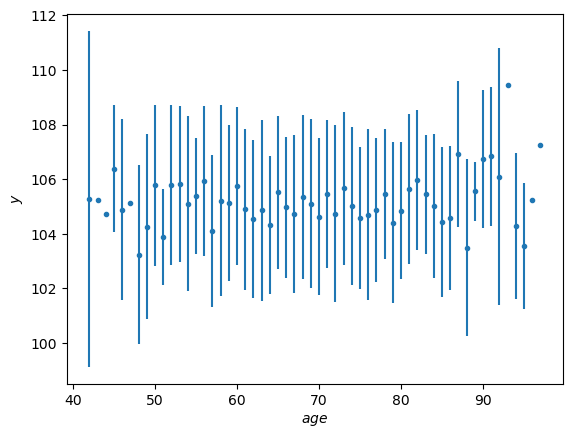

In [6]:
i=5
y = Y[:,i]
age = x[:,1]

df = pd.DataFrame({"age": age, "y": y})
stats = df.groupby("age")["y"].agg(["mean", "std", "count"]).reset_index()


plt.errorbar(stats["age"], stats["mean"], yerr=stats["std"], fmt=".")
plt.xlabel("$age$")
plt.ylabel("$y$")
plt.show()

In [7]:
# needs: pip install ipympl
%matplotlib widget

i=2  linear: RMSE=1569.779 AIC=16605.2  quadratic: RMSE=1568.252 AIC=16605.0  cubic: RMSE=1568.252 AIC=16607.0  piecewise: RMSE=1567.931 AIC=16606.5


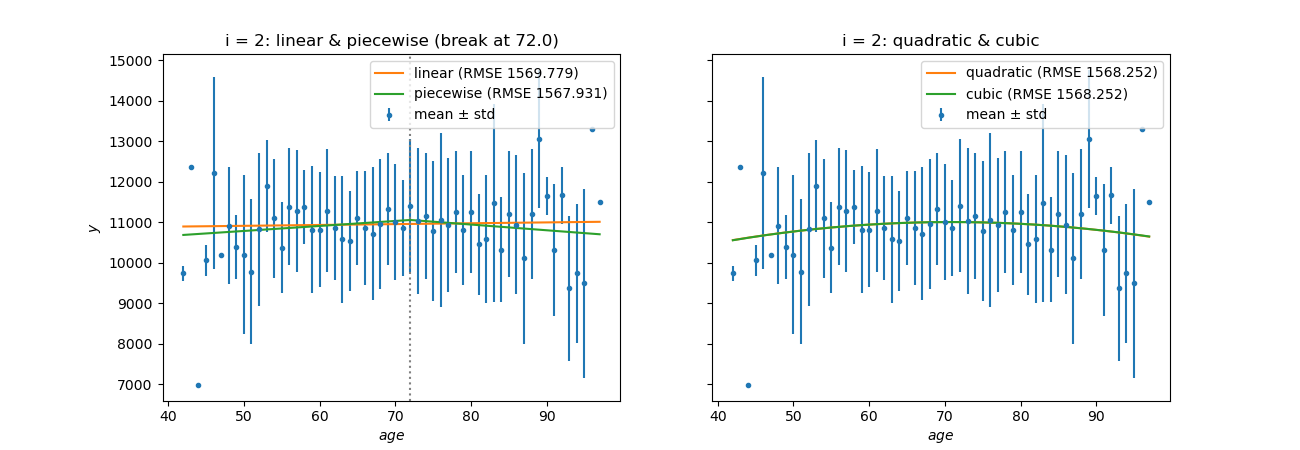

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

age = x[:, 1]
n_cols = Y.shape[1]
state = {"i": 2}

# ---------- models ----------
def fit_poly(a, y, deg):
    coeffs = np.polyfit(a, y, deg)
    return lambda t: np.polyval(coeffs, t), deg + 1          # predictor, n_params

def fit_piecewise(a, y, n_candidates=50):
    """y = p0 + p1*x + p2*max(0, x - c); scan c, solve the rest by least squares."""
    cands = np.quantile(a, np.linspace(0.1, 0.9, n_candidates))
    best = None
    for c in np.unique(cands):
        A = np.column_stack([np.ones_like(a), a, np.maximum(0, a - c)])
        p, *_ = np.linalg.lstsq(A, y, rcond=None)
        sse = np.sum((y - A @ p) ** 2)
        if best is None or sse < best[0]:
            best = (sse, c, p)
    _, c, p = best
    pred = lambda t: p[0] + p[1]*t + p[2]*np.maximum(0, t - c)
    return pred, 4, c                                         # 4 params: a, b, d, c

def fit_all(a, y):
    models = {
        "linear": fit_poly(a, y, 1),
        "quadratic": fit_poly(a, y, 2),
        "cubic": fit_poly(a, y, 3),
    }
    pw_pred, pw_k, c = fit_piecewise(a, y)
    models["piecewise"] = (pw_pred, pw_k)
    return models, c

def residual_stats(a, y, models):
    out, n = {}, len(y)
    for name, (pred, k) in models.items():
        res = y - pred(a)                                     # residuals: data - fit
        sse = np.sum(res**2)
        out[name] = {"residuals": res,
                     "rmse": np.sqrt(sse / n),
                     "aic": n * np.log(sse / n) + 2 * k}
    return out

# ---------- controls ----------
slider = widgets.IntSlider(value=state["i"], min=0, max=n_cols - 1, description="i")
prev_btn = widgets.Button(description="◀ prev")
next_btn = widgets.Button(description="next ▶")
display(widgets.HBox([prev_btn, slider, next_btn]))

# ---------- one figure, two panels ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

def draw():
    i = state["i"]
    y = Y[:, i]

    df = pd.DataFrame({"age": age, "y": y})
    stats = df.groupby("age")["y"].agg(["mean", "std"]).reset_index()

    mask = ~np.isnan(y)
    a, yy = age[mask], y[mask]
    models, c = fit_all(a, yy)
    res = residual_stats(a, yy, models)
    state["res"] = res                      # e.g. state["res"]["cubic"]["residuals"]

    print(f"i={i}  " + "  ".join(f"{n}: RMSE={r['rmse']:.3f} AIC={r['aic']:.1f}" for n, r in res.items()))

    xs = np.linspace(a.min(), a.max(), 300)
    for ax, names in [(ax1, ["linear", "piecewise"]), (ax2, ["quadratic", "cubic"])]:
        ax.clear()
        ax.errorbar(stats["age"], stats["mean"], yerr=stats["std"], fmt=".", label="mean ± std")
        for n in names:
            ax.plot(xs, models[n][0](xs), label=f"{n} (RMSE {res[n]['rmse']:.3f})")
        ax.set_xlabel("$age$")
        ax.legend()

    ax1.axvline(c, ls=":", color="gray")
    ax1.set_ylabel("$y$")
    ax1.set_title(f"i = {i}: linear & piecewise (break at {c:.1f})")
    ax2.set_title(f"i = {i}: quadratic & cubic")
    fig.canvas.draw_idle()

# ---------- wiring ----------
def set_i(new):
    state["i"] = int(new) % n_cols
    slider.value = state["i"]               # triggers draw via the observer

slider.observe(lambda ch: (state.update(i=ch["new"]), draw()), names="value")
prev_btn.on_click(lambda _: set_i(state["i"] - 1))
next_btn.on_click(lambda _: set_i(state["i"] + 1))

draw()

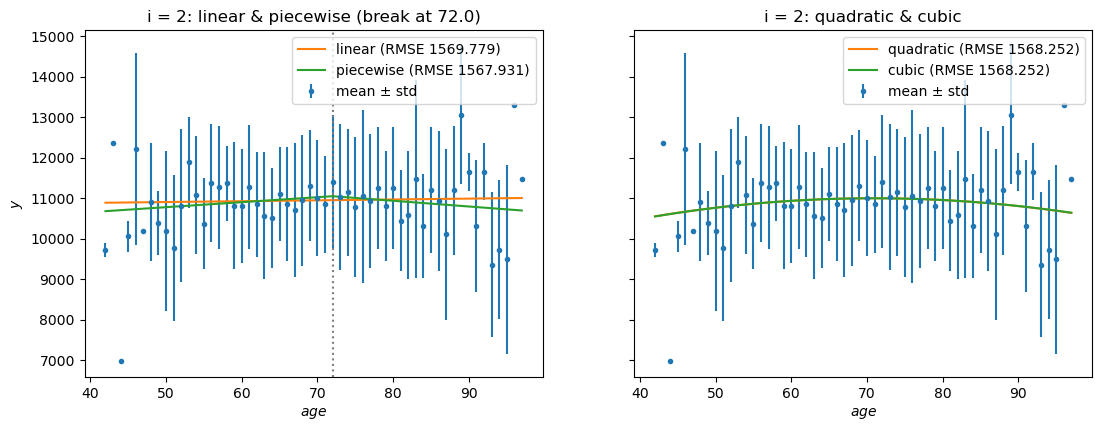

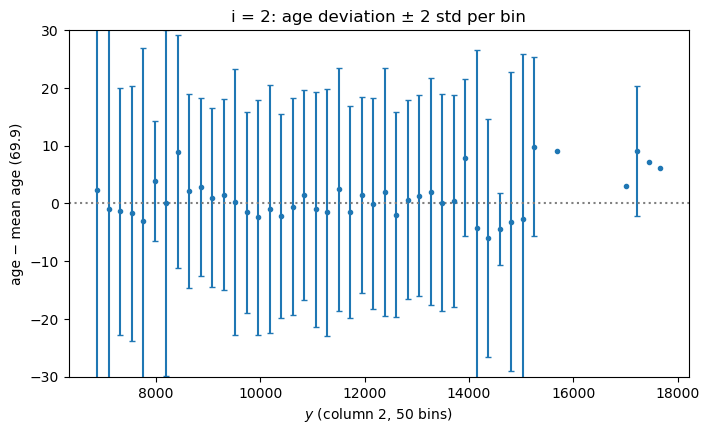

,mean,std,count,center
0,2.246581,20.562333,7,6868.6865
1,-0.896277,25.455844,2,7094.4590
2,-1.324848,10.690450,7,7314.7245
3,-1.729610,11.052903,6,7534.9900
4,-3.096277,15.006665,5,7755.2555
5,3.853723,5.188127,4,7975.5210
6,0.103723,14.993332,6,8195.7865
7,8.960866,10.090071,7,8416.0520
8,2.103723,8.383658,15,8636.3180
9,2.853723,7.672100,28,8856.5835


interactive(children=(IntSlider(value=2, description='i', max=832), Output()), _dom_classes=('widget-interact'…

In [9]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

age = x[:, 1]
n_cols = Y.shape[1]
n_bins = 50

def age_by_bin(i, n_bins=n_bins):
    df = pd.DataFrame({"age": age, "y": Y[:, i]}).dropna()
    mu = df["age"].mean()                                    # overall mean age (rows with valid y)
    df["dev"] = df["age"] - mu                               # deviation from mean age
    df["bin"] = pd.cut(df["y"], bins=n_bins)
    g = df.groupby("bin", observed=False)["dev"].agg(["mean", "std", "count"])
    g["center"] = [b.mid for b in g.index]
    return g.reset_index(drop=True), mu

def draw(i=2):
    g, mu = age_by_bin(i)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(g["center"], g["mean"], yerr=2 * g["std"], fmt=".", capsize=2)
    ax.set_ylim(-30, 30)
    ax.axhline(0, ls=":", color="gray")                      # 0 = overall mean age
    ax.set_xlabel(f"$y$ (column {i}, {n_bins} bins)")
    ax.set_ylabel(f"age − mean age ({mu:.1f})")
    ax.set_title(f"i = {i}: age deviation ± 2 std per bin")
    plt.show()
    return g

# slider (needs working ipywidgets):
import ipywidgets as widgets
widgets.interact(draw, i=widgets.IntSlider(value=2, min=0, max=n_cols - 1));

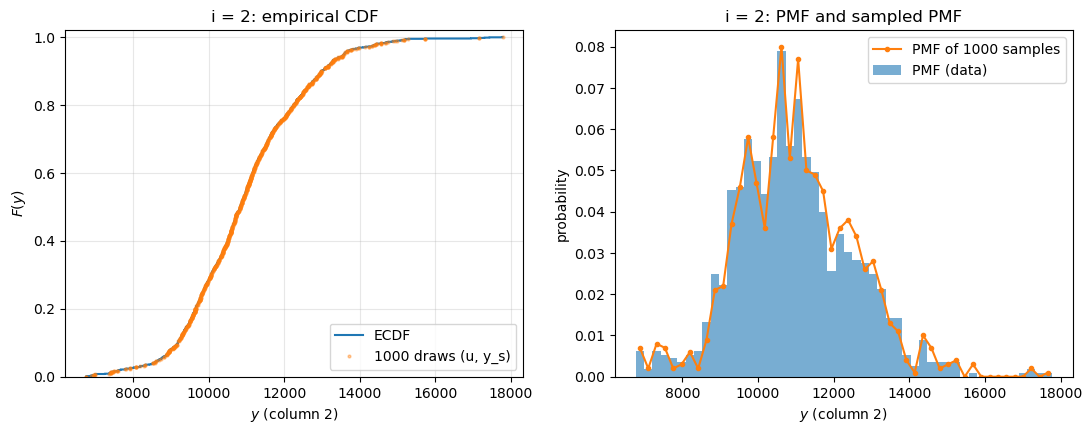

array([11305.2292253 ,  9928.32886372,  8581.18564159,  7583.21549583,
       12331.32453619, 13150.2930281 , 11189.479871  , 11740.47807196,
       10985.99646601, 13350.31561198, 12338.06022225,  6896.11165058,
       12660.66121734,  8314.25695745, 11745.30301823,  9563.04314648,
       12724.10782763, 10980.56860992, 10066.94653026, 10584.93264652,
        8091.38490856,  9305.67132728, 11464.42354024, 11351.10473064,
       11219.02872729, 10442.47452243, 17151.28180744, 14552.94472644,
       11538.6854518 , 11365.14757962, 11542.34044402, 10475.02023794,
        9359.20228813, 11698.71732196, 10928.75811634, 10106.29948214,
       10787.60534461, 12934.16198899, 13337.60698726, 10346.01691988,
       11070.15969577, 10175.76528347, 11147.97276821, 10252.39980688,
       10478.42032993, 12936.88027267,  9770.83518642, 11247.61717559,
        9057.81509861, 12486.73789233, 12172.7894056 ,  9810.40765021,
       12832.08132627,  8824.20947455, 10244.65543218,  9457.43949411,
      

interactive(children=(IntSlider(value=2, description='i', max=832), IntSlider(value=0, description='seed', max…

In [10]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

n_cols = Y.shape[1]
n_bins = 50
n_samp = 1000

def draw_both(i=2, seed=0):
    rng = np.random.default_rng(seed)
    y = Y[:, i]
    y = np.sort(y[~np.isnan(y)])
    n = len(y)
    F = np.arange(1, n + 1) / n                              # ECDF

    # 200 samples off the CDF: u ~ U(0,1), y_s = F^{-1}(u)
    u = rng.uniform(size=n_samp)
    s = np.quantile(y, u, method="inverted_cdf")

    # PMF of the full data and of the sampled values, on the same support
    vals, counts = np.unique(y, return_counts=True)
    if len(vals) <= n_bins:                                  # discrete: exact values
        centers = vals
        p = counts / n
        p_s = np.array([(s == v).mean() for v in vals])
        width = np.diff(vals).min() * 0.8 if len(vals) > 1 else 1.0
    else:                                                    # otherwise: binned
        counts, edges = np.histogram(y, bins=n_bins)
        centers = (edges[:-1] + edges[1:]) / 2
        p = counts / n
        p_s = np.histogram(s, bins=edges)[0] / n_samp
        width = np.diff(edges)

    fig, (axc, axp) = plt.subplots(1, 2, figsize=(13, 4.5))

    axc.step(y, F, where="post", label="ECDF")
    axc.plot(s, u, ".", alpha=0.4, ms=4, label=f"{n_samp} draws (u, y_s)")
    axc.set_ylim(0, 1.02)
    axc.set_xlabel(f"$y$ (column {i})")
    axc.set_ylabel("$F(y)$")
    axc.set_title(f"i = {i}: empirical CDF")
    axc.legend(loc="lower right")
    axc.grid(alpha=0.3)

    axp.bar(centers, p, width=width, alpha=0.6, label="PMF (data)")
    axp.plot(centers, p_s, "o-", color="C1", ms=3, label=f"PMF of {n_samp} samples")
    axp.set_xlabel(f"$y$ (column {i})")
    axp.set_ylabel("probability")
    axp.set_title(f"i = {i}: PMF and sampled PMF")
    axp.legend()

    plt.show()
    return s

# slider (needs working ipywidgets):
widgets.interact(draw_both, i=widgets.IntSlider(value=2, min=0, max=n_cols - 1), seed=(0, 20));

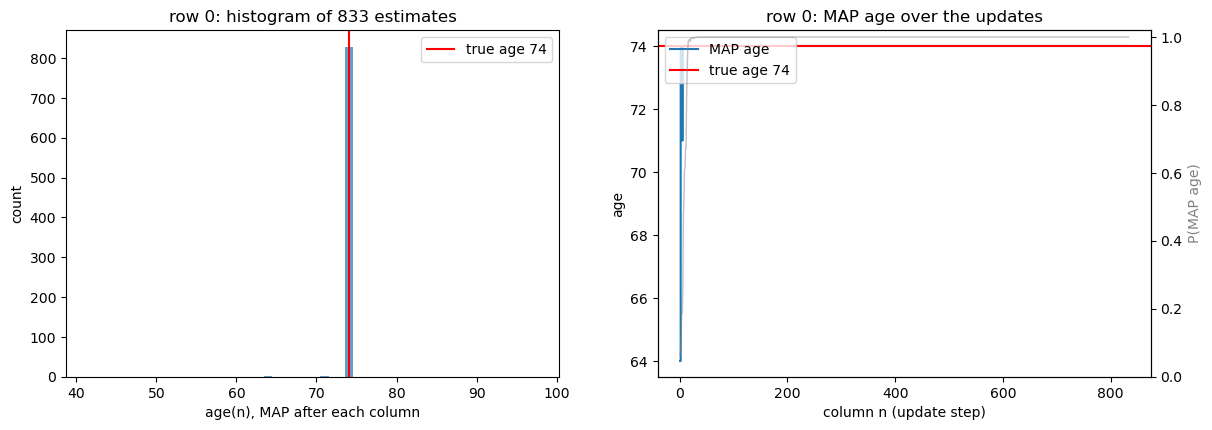

interactive(children=(IntSlider(value=0, description='r', max=1211), Dropdown(description='use', options=('MAP…

In [11]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

n_rows, n_cols = Y.shape
n_bins = 50
alpha = 1.0          # Laplace smoothing for the likelihood table
prior_sd = 10.0      # width of the Gaussian prior around age 70

age = x[:, 1]
has_age = ~np.isnan(age)
grid = np.unique(age[has_age])                       # candidate ages
n_a = len(grid)
a_idx = np.full(n_rows, -1)
a_idx[has_age] = np.searchsorted(grid, age[has_age])

# prior: Gaussian around 70, same for every row (log scale)
logpost = np.tile(-0.5 * ((grid - 70) / prior_sd) ** 2, (n_rows, 1))

age_map = np.zeros((n_rows, n_cols))                 # posterior mode after each column
p_map   = np.zeros((n_rows, n_cols))                 # posterior probability of that mode
age_mean = np.zeros((n_rows, n_cols))                # posterior mean after each column
rows_ar = np.arange(n_rows)

for j in range(n_cols):
    y = Y[:, j]
    valid = ~np.isnan(y)
    if valid.any():
        edges = np.histogram_bin_edges(y[valid], bins=n_bins)
        b = np.full(n_rows, -1)
        b[valid] = np.clip(np.digitize(y[valid], edges[1:-1]), 0, n_bins - 1)

        # likelihood table P(bin | age) from rows with both values
        use = valid & has_age
        counts = np.bincount(a_idx[use] * n_bins + b[use],
                             minlength=n_a * n_bins).reshape(n_a, n_bins)
        logL = np.log((counts + alpha) / (counts.sum(1, keepdims=True) + alpha * n_bins))

        logpost[valid] += logL[:, b[valid]].T        # Bayes update; rows with NaN are skipped
        logpost -= logpost.max(1, keepdims=True)     # keep numbers stable

    post = np.exp(logpost)
    post /= post.sum(1, keepdims=True)               # posterior = next prior
    k = post.argmax(1)
    age_map[:, j] = grid[k]
    p_map[:, j] = post[rows_ar, k]
    age_mean[:, j] = post @ grid

# histogram of the ~n_cols age estimates for one row, with the true age
def draw_row(r=0, use="MAP"):
    est = age_map[r] if use == "MAP" else age_mean[r]
    steps = np.arange(1, n_cols + 1)

    fig, (axh, axt) = plt.subplots(1, 2, figsize=(14, 4.5))

    # left: histogram of the sequential estimates
    axh.hist(est, bins=np.arange(grid.min() - 0.5, grid.max() + 1.5, 1), alpha=0.7)
    axh.axvline(age[r], color="red", label=f"true age {age[r]:.0f}")
    axh.set_xlabel(f"age(n), {use} after each column")
    axh.set_ylabel("count")
    axh.set_title(f"row {r}: histogram of {n_cols} estimates")
    axh.legend()

    # right: development of the estimate over the columns
    axt.step(steps, est, where="post", label=f"{use} age")
    axt.axhline(age[r], color="red", label=f"true age {age[r]:.0f}")
    axt.set_xlabel("column n (update step)")
    axt.set_ylabel("age")
    axt.set_title(f"row {r}: {use} age over the updates")
    axt.legend(loc="upper left")

    axp = axt.twinx()                                   # posterior probability of the MAP
    axp.plot(steps, p_map[r], color="gray", alpha=0.5, lw=1)
    axp.set_ylabel("P(MAP age)", color="gray")
    axp.set_ylim(0, 1.02)

    plt.show()

widgets.interact(draw_row, r=widgets.IntSlider(value=0, min=0, max=n_rows - 1),
                 use=["MAP", "mean"]);

columns: max |rho| = 0.60, #|rho|>0.1: 205, #|rho|>0.2: 138, #|rho|>0.3: 65


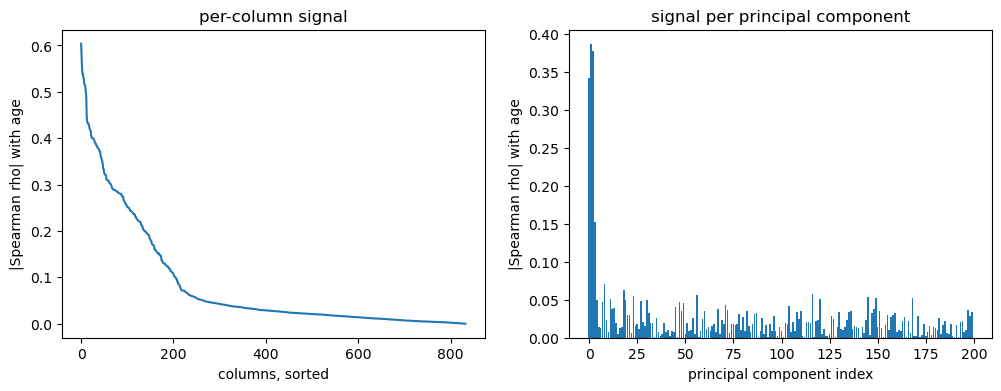

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

known = ~np.isnan(age)
Yk, ak = Y[known], age[known]

# per-column rank correlation with age (diagnostic only, not an evaluation)
rho = np.array([spearmanr(Yk[:, j], ak, nan_policy="omit")[0] for j in range(Y.shape[1])])
absrho = np.abs(rho)
print(f"columns: max |rho| = {np.nanmax(absrho):.2f}, "
      f"#|rho|>0.1: {(absrho > 0.1).sum()}, #|rho|>0.2: {(absrho > 0.2).sum()}, #|rho|>0.3: {(absrho > 0.3).sum()}")

# correlation of each principal component with age
n_pc = 200
Z = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  PCA(n_components=n_pc, random_state=0)).fit_transform(Yk)
rho_pc = np.array([spearmanr(Z[:, k], ak)[0] for k in range(n_pc)])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(np.sort(absrho[~np.isnan(absrho)])[::-1])
a1.set_xlabel("columns, sorted"); a1.set_ylabel("|Spearman rho| with age"); a1.set_title("per-column signal")
a2.bar(np.arange(n_pc), np.abs(rho_pc))
a2.set_xlabel("principal component index"); a2.set_ylabel("|Spearman rho| with age"); a2.set_title("signal per principal component")
plt.show()


columns with eta^2 > 0.05: 125,  rho^2 > 0.05: 116
columns with clear non-monotonic dependence (eta^2 > 0.05, rho^2 < 0.01): 0


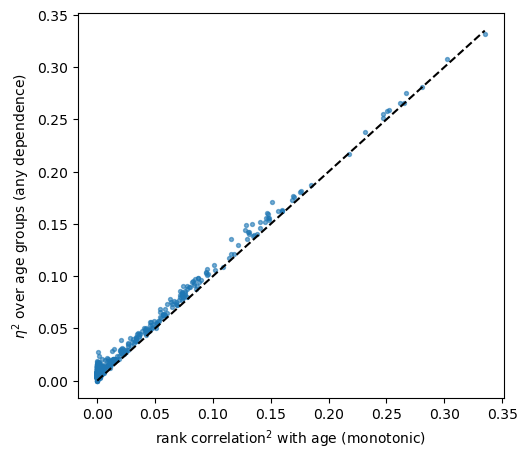

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.impute import SimpleImputer

known = ~np.isnan(age)
Yk, ak = Y[known], age[known]
Yi = SimpleImputer(strategy="median").fit_transform(Yk)
Yr = np.apply_along_axis(rankdata, 0, Yi)              # rank-transform columns (robust to outliers)

# squared rank correlation with age (monotonic dependence only)
ar = rankdata(ak)
Ys = (Yr - Yr.mean(0)) / (Yr.std(0) + 1e-12)
rho2 = ((Ys * ((ar - ar.mean()) / ar.std())[:, None]).mean(0)) ** 2

# correlation ratio eta^2 over 10 age groups (any dependence)
g = pd.qcut(ak, 10, labels=False, duplicates="drop")
tot = Yr.var(0) * len(ak)
between = sum((g == c).sum() * (Yr[g == c].mean(0) - Yr.mean(0)) ** 2 for c in np.unique(g))
eta2 = between / (tot + 1e-12)

nonlin = (eta2 > 0.05) & (rho2 < 0.01)
print(f"columns with eta^2 > 0.05: {(eta2 > 0.05).sum()},  rho^2 > 0.05: {(rho2 > 0.05).sum()}")
print(f"columns with clear non-monotonic dependence (eta^2 > 0.05, rho^2 < 0.01): {nonlin.sum()}")

plt.figure(figsize=(5.5, 5))
plt.scatter(rho2, eta2, s=8, alpha=0.6)
plt.plot([0, rho2.max()], [0, rho2.max()], "k--")
plt.xlabel("rank correlation$^2$ with age (monotonic)"); plt.ylabel("$\\eta^2$ over age groups (any dependence)")
plt.show()


In [14]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.decomposition import PCA

known_idx = np.where(~np.isnan(age))[0]
Yk, ak = Y[known_idx], age[known_idx]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as before
k_list = [10, 20, 40]
deg_list = [1, 2, 3]

def basis(a, am, asd, deg):
    return np.vander((a - am) / asd, deg + 1, increasing=True)

def fit_poly(Z, a_tr, am, asd, deg):
    B = basis(a_tr, am, asd, deg)
    coef, *_ = np.linalg.lstsq(B, Z, rcond=None)
    s2 = ((Z - B @ coef) ** 2).sum(0) / (len(a_tr) - deg - 1)
    return coef, s2

def posterior(Z_te, coef, s2, grid, am, asd, deg):
    mean = basis(grid, am, asd, deg) @ coef
    ll = -0.5 * (((Z_te[:, None, :] - mean[None]) ** 2) / s2).sum(2)
    lpost = ll - 0.5 * ((grid - am) / asd) ** 2
    lpost -= lpost.max(1, keepdims=True)
    post = np.exp(lpost)
    return post / post.sum(1, keepdims=True)

def summarize(grid, post):
    cdf = np.cumsum(post, 1)
    q = lambda u: grid[(cdf >= u).argmax(1)]
    return dict(mean=post @ grid, median=q(0.5), lo=q(0.05), hi=q(0.95))

res = {(k, d): {key: np.zeros(len(ak)) for key in ["mean", "median", "lo", "hi"]}
       for k in k_list for d in deg_list}
for tr, te in cv.split(Yk):
    am, asd = ak[tr].mean(), ak[tr].std()
    grid = np.unique(ak[tr])
    for k in k_list:
        pipe = make_pipeline(SimpleImputer(strategy="median"),
                             QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                             StandardScaler(),
                             PCA(n_components=k, random_state=0))
        Z_tr = pipe.fit_transform(Yk[tr])
        Z_te = pipe.transform(Yk[te])
        for d in deg_list:
            coef, s2 = fit_poly(Z_tr, ak[tr], am, asd, d)
            post = posterior(Z_te, coef, s2, grid, am, asd, d)
            for key, v in summarize(grid, post).items():
                res[(k, d)][key][te] = v

mae = lambda p_: np.mean(np.abs(p_ - ak))
print("ridge plain: 5.92   ridge quantile: 5.62   GB squared_error: 5.37")
print("\n  k  degree  MAE(median)  MAE(mean)  90% coverage")
for (k, d), r in res.items():
    cover = np.mean((ak >= r["lo"]) & (ak <= r["hi"]))
    print(f"{k:3d}  {d:6d}  {mae(r['median']):11.2f}  {mae(r['mean']):9.2f}  {cover:12.2f}")

best = min(res, key=lambda kd: mae(res[kd]["median"]))
p_bayes = res[best]["median"]
print(f"\nbest: k = {best[0]}, degree = {best[1]}, MAE = {mae(p_bayes):.2f}")

# ensembles with the earlier predictions, if they're still in memory
if "pred_q" in globals():
    print(f"average of Bayes and ridge-quantile:  {mae((p_bayes + pred_q) / 2):.2f}")
if "preds" in globals() and "GB squared_error" in preds:
    print(f"average of Bayes and GB:              {mae((p_bayes + preds['GB squared_error']) / 2):.2f}")
    if "pred_q" in globals():
        print(f"average of ridge-quantile and GB:     {mae((pred_q + preds['GB squared_error']) / 2):.2f}")

ridge plain: 5.92   ridge quantile: 5.62   GB squared_error: 5.37

  k  degree  MAE(median)  MAE(mean)  90% coverage
 10       1         5.86       5.88          0.92
 10       2         5.83       5.86          0.92
 10       3         5.74       5.79          0.92
 20       1         5.85       5.86          0.92
 20       2         5.77       5.83          0.92
 20       3         5.72       5.76          0.92
 40       1         5.84       5.85          0.92
 40       2         5.79       5.84          0.91
 40       3         5.76       5.78          0.91

best: k = 20, degree = 3, MAE = 5.72


informative columns (linear R^2 > 0.05): 110
  with a clear hinge (R^2 gain > 0.02):  3
    flat, then rising       0   median knot: nan
    flat, then falling      2   median knot: 67.0
    rising, then flat       0   median knot: nan
    falling, then flat      0   median knot: nan
  hinge but neither shape (e.g. two real slopes): 1
  median R^2 gain over linear (informative): 0.004


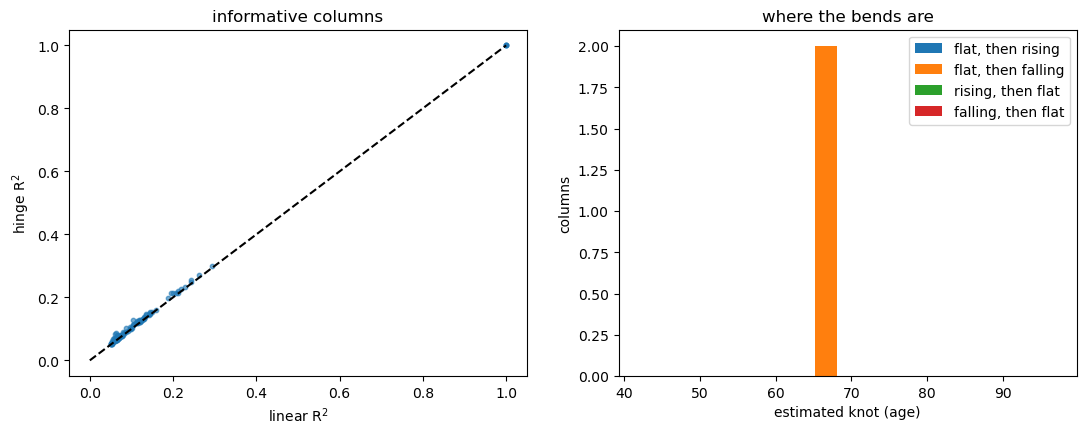

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer

known = ~np.isnan(age)
Yk, ak = Y[known], age[known]
n_k = len(ak)

# quantile-normal transform per column, then standardise
Z = QuantileTransformer(n_quantiles=min(200, n_k), output_distribution="normal", random_state=0)\
        .fit_transform(SimpleImputer(strategy="median").fit_transform(Yk))
Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-12)
sst = (Z ** 2).sum(0)
n_col = Z.shape[1]

# straight-line fit per column
B1 = np.column_stack([np.ones(n_k), ak])
c1, *_ = np.linalg.lstsq(B1, Z, rcond=None)
r2_lin = 1 - ((Z - B1 @ c1) ** 2).sum(0) / sst

# hinge fit per column: a + b*age + d*max(0, age - knot); knot scanned between the 15th and 85th age percentile
knots = np.quantile(ak, np.linspace(0.15, 0.85, 29))
best_sse = np.full(n_col, np.inf)
best_knot = np.zeros(n_col); slope1 = np.zeros(n_col); slope2 = np.zeros(n_col)
for c in knots:
    B = np.column_stack([np.ones(n_k), ak, np.maximum(0, ak - c)])
    coef, *_ = np.linalg.lstsq(B, Z, rcond=None)
    sse = ((Z - B @ coef) ** 2).sum(0)
    better = sse < best_sse
    best_sse[better] = sse[better]; best_knot[better] = c
    slope1[better] = coef[1][better]; slope2[better] = (coef[1] + coef[2])[better]
r2_hinge = 1 - best_sse / sst
gain = r2_hinge - r2_lin

# classify the informative columns
inform = r2_lin > 0.05                                           # informative columns
hockey = inform & (gain > 0.02)                                  # clear hinge
flat_then = hockey & (np.abs(slope1) < 0.3 * np.abs(slope2))     # flat below the knot, then slope
slope_then = hockey & (np.abs(slope2) < 0.3 * np.abs(slope1))    # slope below the knot, then flat
sloped = np.where(flat_then, slope2, slope1)                     # the non-flat slope
groups = {
    "flat, then rising":  flat_then & (sloped > 0),
    "flat, then falling": flat_then & (sloped < 0),
    "rising, then flat":  slope_then & (sloped > 0),
    "falling, then flat": slope_then & (sloped < 0),
}

print(f"informative columns (linear R^2 > 0.05): {inform.sum()}")
print(f"  with a clear hinge (R^2 gain > 0.02):  {hockey.sum()}")
for name, m in groups.items():
    print(f"    {name:20s} {m.sum():4d}   median knot: {np.median(best_knot[m]) if m.any() else float('nan'):.1f}")
print(f"  hinge but neither shape (e.g. two real slopes): {(hockey & ~flat_then & ~slope_then).sum()}")
print(f"  median R^2 gain over linear (informative): {np.median(gain[inform]):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.scatter(r2_lin[inform], r2_hinge[inform], s=10, alpha=0.6)
a1.plot([0, r2_hinge.max()], [0, r2_hinge.max()], "k--")
a1.set_xlabel("linear R$^2$"); a1.set_ylabel("hinge R$^2$"); a1.set_title("informative columns")

bins = np.linspace(ak.min(), ak.max(), 20)
a2.hist([best_knot[m] for m in groups.values()], bins=bins, stacked=True, label=list(groups.keys()))
a2.set_xlabel("estimated knot (age)"); a2.set_ylabel("columns"); a2.set_title("where the bends are")
a2.legend()
plt.show()

In [16]:
j = np.nanargmax(r2_lin)
col = Yk[:, j]
print("column", j, " R2 linear:", r2_lin[j])
print("NaN fraction:", np.isnan(col).mean(), " distinct values:", len(np.unique(col[~np.isnan(col)])))
print(np.c_[ak, col][:15])

column 105  R2 linear: 1.0
NaN fraction: 0.06848184818481848  distinct values: 1
[[74.  0.]
 [51.  0.]
 [70.  0.]
 [52.  0.]
 [85.  0.]
 [59. nan]
 [82.  0.]
 [72.  0.]
 [73.  0.]
 [56.  0.]
 [83.  0.]
 [65.  0.]
 [63.  0.]
 [64.  0.]
 [64.  0.]]


In [17]:
n_distinct = np.array([len(np.unique(Y[~np.isnan(Y[:, j]), j])) for j in range(Y.shape[1])])
print((n_distinct <= 1).sum(), "constant columns")
print((n_distinct <= 5).sum(), "columns with 5 or fewer distinct values")
print(np.where(n_distinct <= 5)[0])

4 constant columns
4 columns with 5 or fewer distinct values
[105 130 490 531]


In [18]:
keep = n_distinct > 1
col_ids = np.where(keep)[0]            # col_ids[new_index] = original column number
Y = Y[:, keep]
n_cols = Y.shape[1]
print(Y.shape)

(1212, 829)


informative columns (linear R^2 > 0.05): 106
  with a clear hinge (R^2 gain > 0.02):  3
    flat, then rising       0   median knot: nan
    flat, then falling      2   median knot: 67.0
    rising, then flat       0   median knot: nan
    falling, then flat      0   median knot: nan
  hinge but neither shape (e.g. two real slopes): 1
  median R^2 gain over linear (informative): 0.004


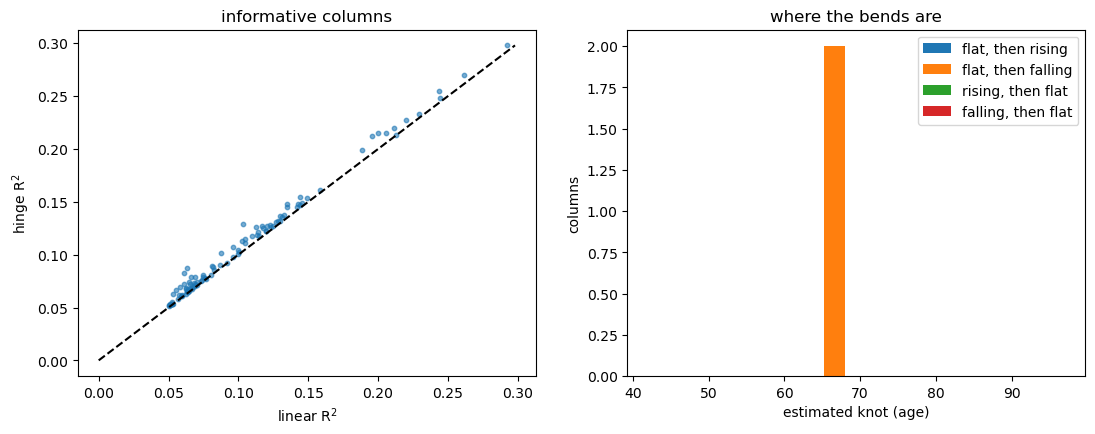

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer

known = ~np.isnan(age)
Yk, ak = Y[known], age[known]
n_k = len(ak)

# quantile-normal transform per column, then standardise
Z = QuantileTransformer(n_quantiles=min(200, n_k), output_distribution="normal", random_state=0)\
        .fit_transform(SimpleImputer(strategy="median").fit_transform(Yk))
Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-12)
sst = (Z ** 2).sum(0)
n_col = Z.shape[1]

# straight-line fit per column
B1 = np.column_stack([np.ones(n_k), ak])
c1, *_ = np.linalg.lstsq(B1, Z, rcond=None)
r2_lin = 1 - ((Z - B1 @ c1) ** 2).sum(0) / sst

# hinge fit per column: a + b*age + d*max(0, age - knot); knot scanned between the 15th and 85th age percentile
knots = np.quantile(ak, np.linspace(0.15, 0.85, 29))
best_sse = np.full(n_col, np.inf)
best_knot = np.zeros(n_col); slope1 = np.zeros(n_col); slope2 = np.zeros(n_col)
for c in knots:
    B = np.column_stack([np.ones(n_k), ak, np.maximum(0, ak - c)])
    coef, *_ = np.linalg.lstsq(B, Z, rcond=None)
    sse = ((Z - B @ coef) ** 2).sum(0)
    better = sse < best_sse
    best_sse[better] = sse[better]; best_knot[better] = c
    slope1[better] = coef[1][better]; slope2[better] = (coef[1] + coef[2])[better]
r2_hinge = 1 - best_sse / sst
gain = r2_hinge - r2_lin

# classify the informative columns
inform = r2_lin > 0.05                                           # informative columns
hockey = inform & (gain > 0.02)                                  # clear hinge
flat_then = hockey & (np.abs(slope1) < 0.3 * np.abs(slope2))     # flat below the knot, then slope
slope_then = hockey & (np.abs(slope2) < 0.3 * np.abs(slope1))    # slope below the knot, then flat
sloped = np.where(flat_then, slope2, slope1)                     # the non-flat slope
groups = {
    "flat, then rising":  flat_then & (sloped > 0),
    "flat, then falling": flat_then & (sloped < 0),
    "rising, then flat":  slope_then & (sloped > 0),
    "falling, then flat": slope_then & (sloped < 0),
}

print(f"informative columns (linear R^2 > 0.05): {inform.sum()}")
print(f"  with a clear hinge (R^2 gain > 0.02):  {hockey.sum()}")
for name, m in groups.items():
    print(f"    {name:20s} {m.sum():4d}   median knot: {np.median(best_knot[m]) if m.any() else float('nan'):.1f}")
print(f"  hinge but neither shape (e.g. two real slopes): {(hockey & ~flat_then & ~slope_then).sum()}")
print(f"  median R^2 gain over linear (informative): {np.median(gain[inform]):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.scatter(r2_lin[inform], r2_hinge[inform], s=10, alpha=0.6)
a1.plot([0, r2_hinge.max()], [0, r2_hinge.max()], "k--")
a1.set_xlabel("linear R$^2$"); a1.set_ylabel("hinge R$^2$"); a1.set_title("informative columns")

bins = np.linspace(ak.min(), ak.max(), 20)
a2.hist([best_knot[m] for m in groups.values()], bins=bins, stacked=True, label=list(groups.keys()))
a2.set_xlabel("estimated knot (age)"); a2.set_ylabel("columns"); a2.set_title("where the bends are")
a2.legend()
plt.show()

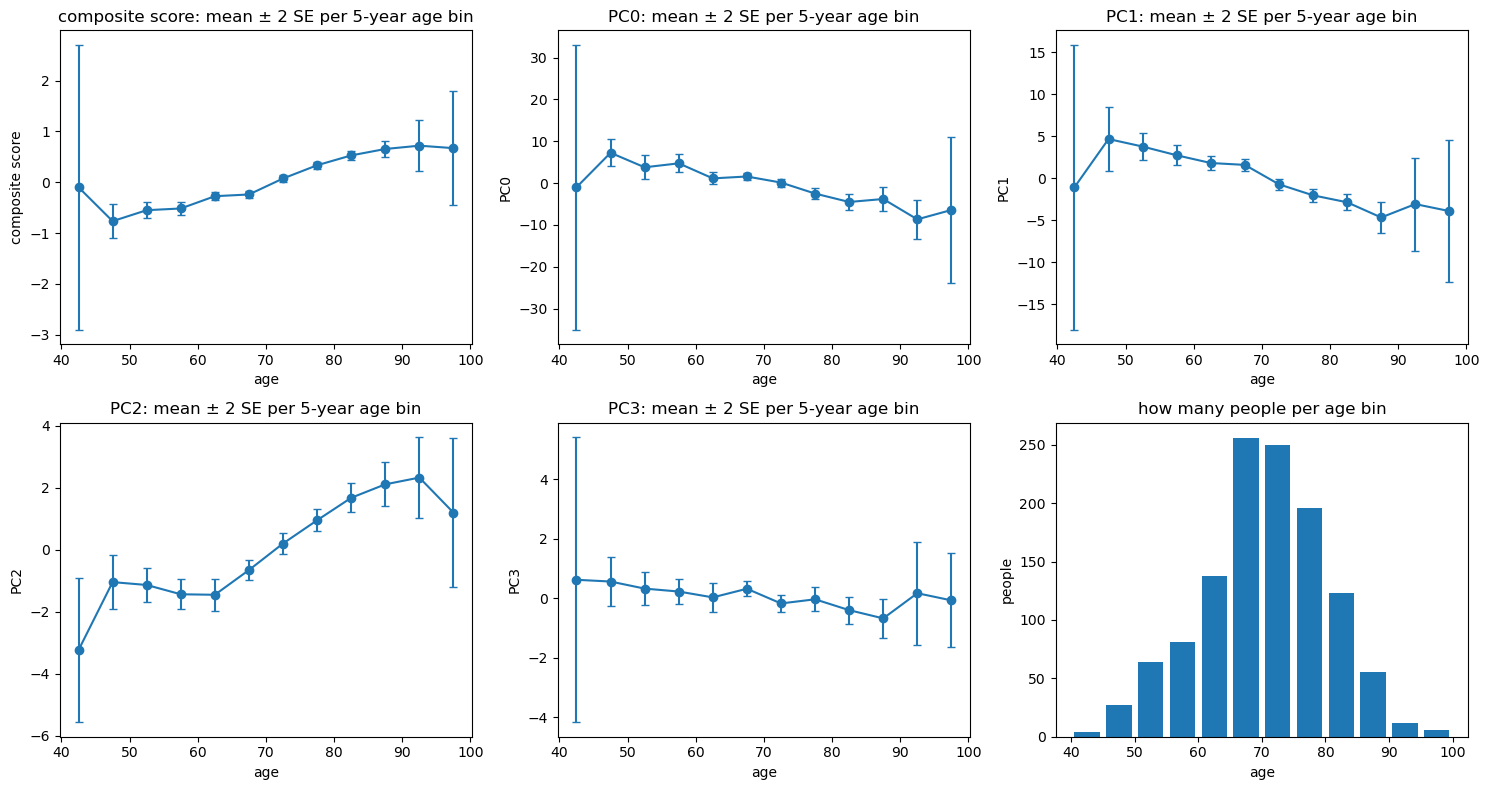

columns used for the score: 60  counts per bin: {np.int64(42): np.int64(4), np.int64(47): np.int64(27), np.int64(52): np.int64(64), np.int64(57): np.int64(81), np.int64(62): np.int64(138), np.int64(67): np.int64(256), np.int64(72): np.int64(250), np.int64(77): np.int64(196), np.int64(82): np.int64(123), np.int64(87): np.int64(55), np.int64(92): np.int64(12), np.int64(97): np.int64(6)}


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# uses Z, ak and r2_lin from the previous cell
r2 = np.nan_to_num(r2_lin, nan=0.0)
use = (r2 < 0.9)                                          # leave out the suspicious column(s)
Zc = Z[:, use]
age_std = (ak - ak.mean()) / ak.std()
corr = (Zc * age_std[:, None]).mean(0)                    # Pearson correlation of each column with age
r2c = r2[use]

# composite score: top informative columns, signs aligned with their correlation to age
top = np.where(r2c > 0.05)[0]
top = top[np.argsort(-r2c[top])][:60]
score = (Zc[:, top] * np.sign(corr[top])).mean(1)

pcs = PCA(n_components=4, random_state=0).fit_transform(Zc)
series = [("composite score", score)] + [(f"PC{k}", pcs[:, k]) for k in range(4)]

edges = np.arange(40, 105, 5)
which = np.digitize(ak, edges) - 1
centers = (edges[:-1] + edges[1:]) / 2
counts = np.array([(which == b).sum() for b in range(len(centers))])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, s) in zip(axes.ravel(), series):
    mean = np.array([s[which == b].mean() if counts[b] > 2 else np.nan for b in range(len(centers))])
    se = np.array([s[which == b].std(ddof=1) / np.sqrt(counts[b]) if counts[b] > 2 else np.nan for b in range(len(centers))])
    ax.errorbar(centers, mean, yerr=2 * se, fmt="o-", capsize=3)
    ax.set_xlabel("age"); ax.set_ylabel(name); ax.set_title(f"{name}: mean ± 2 SE per 5-year age bin")
ax = axes.ravel()[5]
ax.bar(centers, counts, width=4)
ax.set_xlabel("age"); ax.set_ylabel("people"); ax.set_title("how many people per age bin")
fig.tight_layout()
plt.show()
print("columns used for the score:", len(top), " counts per bin:", dict(zip(centers.astype(int), counts)))

In [21]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.decomposition import PCA

known_idx = np.where(~np.isnan(age))[0]
Yk, ak = Y[known_idx], age[known_idx]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as before

k_list = [10, 20]                                     # PCA components
knot_options = [(65,), (65, 85), (60, 70, 80), (55, 65, 75, 85)]
lam_list = [0, 30]                                    # ridge penalty on the bend terms

def basis(a, am, asd, knots):
    cols = [np.ones_like(a, dtype=float), (a - am) / asd] + [np.maximum(0, a - kn) / asd for kn in knots]
    return np.column_stack(cols)

def fit_spline(Z, a_tr, am, asd, knots, lam):
    B = basis(a_tr, am, asd, knots)
    P = np.diag([0, 0] + [1] * len(knots)).astype(float)         # penalise only the bend terms
    coef = np.linalg.solve(B.T @ B + lam * P, B.T @ Z)
    s2 = ((Z - B @ coef) ** 2).sum(0) / (len(a_tr) - B.shape[1])
    return coef, s2

def posterior(Z_te, coef, s2, grid, am, asd, knots):
    mean = basis(grid, am, asd, knots) @ coef                     # (G, k)
    ll = -0.5 * (((Z_te[:, None, :] - mean[None]) ** 2) / s2).sum(2)
    lpost = ll - 0.5 * ((grid - am) / asd) ** 2                   # + Gaussian prior on age
    lpost -= lpost.max(1, keepdims=True)
    post = np.exp(lpost)
    return post / post.sum(1, keepdims=True)

def summarize(grid, post):
    cdf = np.cumsum(post, 1)
    q = lambda u: grid[(cdf >= u).argmax(1)]
    return dict(median=q(0.5), lo=q(0.05), hi=q(0.95))

combos = [(k, kn, lam) for k in k_list for kn in knot_options for lam in lam_list]
res = {c: {key: np.zeros(len(ak)) for key in ["median", "lo", "hi"]} for c in combos}
for tr, te in cv.split(Yk):
    am, asd = ak[tr].mean(), ak[tr].std()
    grid = np.unique(ak[tr])
    for k in k_list:
        pipe = make_pipeline(SimpleImputer(strategy="median"),
                             QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                             StandardScaler(),
                             PCA(n_components=k, random_state=0))
        Z_tr = pipe.fit_transform(Yk[tr])
        Z_te = pipe.transform(Yk[te])
        for kn in knot_options:
            for lam in lam_list:
                coef, s2 = fit_spline(Z_tr, ak[tr], am, asd, kn, lam)
                post = posterior(Z_te, coef, s2, grid, am, asd, kn)
                for key, v in summarize(grid, post).items():
                    res[(k, kn, lam)][key][te] = v

mae = lambda p_: np.mean(np.abs(p_ - ak))
print("earlier: Bayes cubic 5.72   ridge-quantile 5.62   GB 5.37   ridge-q + GB 5.31")
print("\n  k  knots              lambda  MAE(median)  90% coverage")
for (k, kn, lam), r in res.items():
    cover = np.mean((ak >= r["lo"]) & (ak <= r["hi"]))
    print(f"{k:3d}  {str(kn):18s} {lam:6d}  {mae(r['median']):11.2f}  {cover:12.2f}")

best = min(res, key=lambda c: mae(res[c]["median"]))
p_best = res[best]["median"]
print(f"\nbest: k = {best[0]}, knots = {best[1]}, lambda = {best[2]}, MAE = {mae(p_best):.2f}")
print("MAE by true age group (best):")
for lo, hi in [(40, 55), (55, 65), (65, 75), (75, 85), (85, 100)]:
    m = (ak >= lo) & (ak < hi)
    print(f"  {lo}-{hi}: n={m.sum():4d}  MAE={np.mean(np.abs(p_best[m] - ak[m])):.2f}")

if "pred_q" in globals() and "preds" in globals() and "GB squared_error" in preds:
    gb = preds["GB squared_error"]
    print(f"\naverage of spline-Bayes and GB:             {mae((p_best + gb) / 2):.2f}")
    print(f"average of spline-Bayes, ridge-q and GB:    {mae((p_best + pred_q + gb) / 3):.2f}")

earlier: Bayes cubic 5.72   ridge-quantile 5.62   GB 5.37   ridge-q + GB 5.31

  k  knots              lambda  MAE(median)  90% coverage
 10  (65,)                   0         5.78          0.92
 10  (65,)                  30         5.80          0.92
 10  (65, 85)                0         5.73          0.92
 10  (65, 85)               30         5.78          0.92
 10  (60, 70, 80)            0         5.75          0.92
 10  (60, 70, 80)           30         5.77          0.92
 10  (55, 65, 75, 85)        0         5.75          0.92
 10  (55, 65, 75, 85)       30         5.76          0.92
 20  (65,)                   0         5.77          0.92
 20  (65,)                  30         5.79          0.92
 20  (65, 85)                0         5.74          0.92
 20  (65, 85)               30         5.77          0.92
 20  (60, 70, 80)            0         5.75          0.92
 20  (60, 70, 80)           30         5.76          0.92
 20  (55, 65, 75, 85)        0         5.75        

Default model (Gaussian prior), by true age group:
 age group     n    MAE   bias(pred-true)  median pred   90% coverage  median interval width
  40-50       31  18.26           18.26         64.0          0.16                  25.0
  50-55       64  13.48           13.48         65.0          0.58                  26.0
  55-60       81   9.10            9.10         66.0          0.94                  25.0
  60-65      138   5.41            5.40         67.0          0.99                  25.0
  65-70      256   2.68            1.07         68.0          1.00                  26.0
  70-75      250   2.82           -1.43         70.0          1.00                  26.0
  75-80      196   4.45           -4.23         73.0          0.99                  26.0
  80-85      123   6.99           -6.96         75.0          0.96                  26.0
  85-90       55  10.82          -10.82         77.0          0.76                  25.0
  90-100      18  17.28          -17.28         77.0   

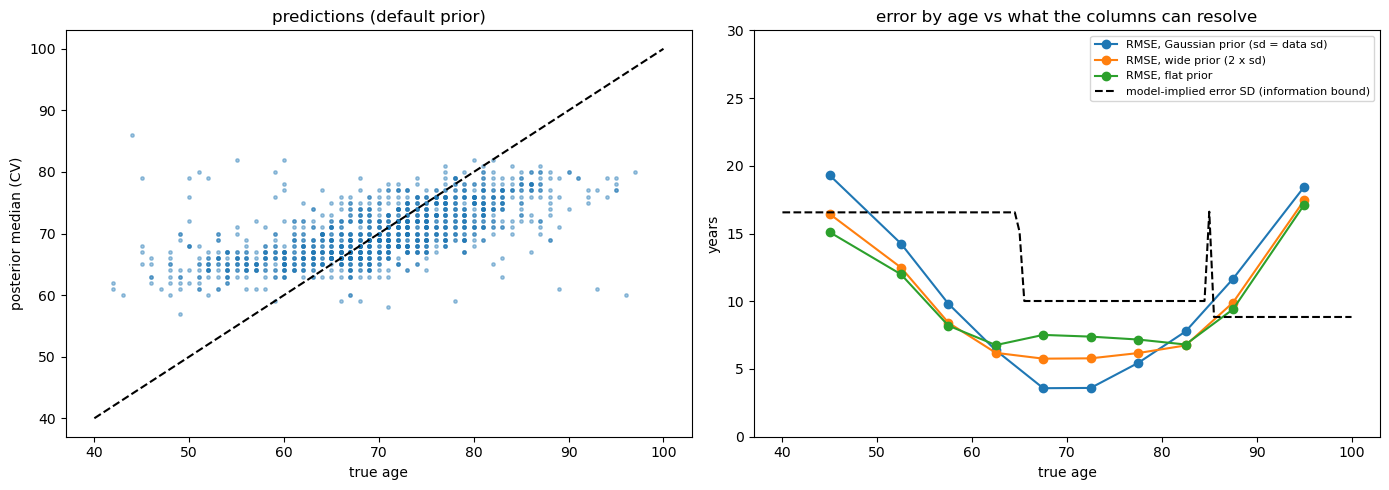

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.decomposition import PCA

known_idx = np.where(~np.isnan(age))[0]
Yk, ak = Y[known_idx], age[known_idx]
cv = KFold(5, shuffle=True, random_state=0)

K, KNOTS, LAM = 10, (65, 85), 0                       # best spline model from the last cell
prior_scales = {"Gaussian prior (sd = data sd)": 1.0, "wide prior (2 x sd)": 2.0, "flat prior": None}

def make_pipe(k):
    return make_pipeline(SimpleImputer(strategy="median"),
                         QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                         StandardScaler(), PCA(n_components=k, random_state=0))

def basis(a, am, asd, knots):
    cols = [np.ones_like(a, dtype=float), (a - am) / asd] + [np.maximum(0, a - kn) / asd for kn in knots]
    return np.column_stack(cols)

def fit_spline(Z, a_tr, am, asd, knots, lam):
    B = basis(a_tr, am, asd, knots)
    P = np.diag([0, 0] + [1] * len(knots)).astype(float)
    coef = np.linalg.solve(B.T @ B + lam * P, B.T @ Z)
    s2 = ((Z - B @ coef) ** 2).sum(0) / (len(a_tr) - B.shape[1])
    return coef, s2

def posterior(Z_te, coef, s2, grid, am, asd, knots, prior_scale):
    mean = basis(grid, am, asd, knots) @ coef
    lpost = -0.5 * (((Z_te[:, None, :] - mean[None]) ** 2) / s2).sum(2)
    if prior_scale is not None:
        lpost = lpost - 0.5 * ((grid - am) / (prior_scale * asd)) ** 2
    lpost -= lpost.max(1, keepdims=True)
    post = np.exp(lpost)
    return post / post.sum(1, keepdims=True)

def summarize(grid, post):
    cdf = np.cumsum(post, 1)
    q = lambda u: grid[(cdf >= u).argmax(1)]
    return q(0.5), q(0.05), q(0.95)

# ---- cross-validated predictions for each prior ----
out = {name: {key: np.zeros(len(ak)) for key in ["med", "lo", "hi"]} for name in prior_scales}
for tr, te in cv.split(Yk):
    am, asd = ak[tr].mean(), ak[tr].std()
    grid = np.unique(ak[tr])
    pipe = make_pipe(K)
    Z_tr = pipe.fit_transform(Yk[tr]); Z_te = pipe.transform(Yk[te])
    coef, s2 = fit_spline(Z_tr, ak[tr], am, asd, KNOTS, LAM)
    for name, sc in prior_scales.items():
        med, lo, hi = summarize(grid, posterior(Z_te, coef, s2, grid, am, asd, KNOTS, sc))
        out[name]["med"][te], out[name]["lo"][te], out[name]["hi"][te] = med, lo, hi

edges = [40, 50, 55, 60, 65, 70, 75, 80, 85, 90, 100]
names = list(prior_scales)
d = out[names[0]]
print("Default model (Gaussian prior), by true age group:")
print(" age group     n    MAE   bias(pred-true)  median pred   90% coverage  median interval width")
for lo_, hi_ in zip(edges[:-1], edges[1:]):
    m = (ak >= lo_) & (ak < hi_)
    err = d["med"][m] - ak[m]
    cov = np.mean((ak[m] >= d["lo"][m]) & (ak[m] <= d["hi"][m]))
    print(f" {lo_:3d}-{hi_:<3d}   {m.sum():5d}  {np.mean(np.abs(err)):5.2f}  {np.mean(err):14.2f}  {np.median(d['med'][m]):11.1f}  {cov:12.2f}  {np.median(d['hi'][m] - d['lo'][m]):20.1f}")

print("\nMAE by true age group for different priors:")
print(" age group     n   " + "   ".join(f"{nm[:22]:>22s}" for nm in names))
for lo_, hi_ in zip(edges[:-1], edges[1:]):
    m = (ak >= lo_) & (ak < hi_)
    print(f" {lo_:3d}-{hi_:<3d}   {m.sum():5d}   " + "   ".join(f"{np.mean(np.abs(out[nm]['med'][m] - ak[m])):22.2f}" for nm in names))
print(" overall      " + f"{len(ak):5d}   " + "   ".join(f"{np.mean(np.abs(out[nm]['med'] - ak)):22.2f}" for nm in names))

# ---- information bound: how well could the model separate ages, from its own mean curves ----
am, asd = ak.mean(), ak.std()
pipe = make_pipe(K); Z = pipe.fit_transform(Yk)
coef, s2 = fit_spline(Z, ak, am, asd, KNOTS, LAM)
g = np.arange(40, 100.5, 0.5)
mean_g = basis(g, am, asd, KNOTS) @ coef                      # mean of each component at each age
dmean = np.gradient(mean_g, g, axis=0)                        # how fast each component changes per year
fisher = (dmean ** 2 / s2).sum(1)                             # information per year about age
sd_bound = 1 / np.sqrt(fisher)                                # approx. best achievable error SD (years), flat prior

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.scatter(ak, d["med"], s=6, alpha=0.4)
a1.plot([40, 100], [40, 100], "k--")
a1.set_xlabel("true age"); a1.set_ylabel("posterior median (CV)"); a1.set_title("predictions (default prior)")

centers = (np.array(edges[:-1]) + np.array(edges[1:])) / 2
for nm in names:
    rm = [np.sqrt(np.mean((out[nm]["med"][(ak >= l) & (ak < h_)] - ak[(ak >= l) & (ak < h_)]) ** 2)) for l, h_ in zip(edges[:-1], edges[1:])]
    a2.plot(centers, rm, "o-", label=f"RMSE, {nm}")
a2.plot(g, sd_bound, "k--", label="model-implied error SD (information bound)")
a2.set_ylim(0, 30); a2.set_xlabel("true age"); a2.set_ylabel("years"); a2.set_title("error by age vs what the columns can resolve")
a2.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [23]:
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import r2_score

# R^2 of the cross-validated predictions already in memory
cands = {}
if "pred" in globals():   cands["ridge"] = pred
if "pred_q" in globals(): cands["ridge, quantile"] = pred_q
if "preds" in globals():  cands.update(preds)
if "p_best" in globals(): cands["Bayes spline"] = p_best
for name, p_ in cands.items():
    print(f"R^2  {name:20s} {r2_score(ak, p_):.3f}")

# what is the first column of x?
print("\nx[:, 0]: distinct values =", len(np.unique(x[:, 0])), " first values:", np.unique(x[:, 0])[:10])

# row-level summaries vs age (Spearman)
rows = {"NaN fraction": np.isnan(Yk).mean(1),
        "zero fraction": (Yk == 0).mean(1),
        "row median": np.nanmedian(Yk, 1),
        "row mean": np.nanmean(Yk, 1),
        "row std": np.nanstd(Yk, 1)}
print("\nrow-level summaries, Spearman correlation with age:")
for name, v in rows.items():
    print(f"  {name:14s} {spearmanr(v, ak, nan_policy='omit')[0]:+.2f}")

R^2  Bayes spline         0.377

x[:, 0]: distinct values = 1212  first values: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]

row-level summaries, Spearman correlation with age:
  NaN fraction   +0.05
  zero fraction  -0.01
  row median     -0.10
  row mean       -0.39
  row std        -0.16


In [24]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

known = ~np.isnan(age)
ak = age[known]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as before

print("index vs age, Spearman:", round(spearmanr(x[known, 0], ak)[0], 3))

def evaluate(F, name):
    model = make_pipeline(SimpleImputer(strategy="median"),
                          QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                          StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 11)))
    p_ = cross_val_predict(model, F[known], ak, cv=cv)
    print(f"{name:34s} R2 {r2_score(ak, p_):.3f}   MAE {np.mean(np.abs(p_ - ak)):.2f}")
    return p_

col_med = np.nanmedian(Y, 0); col_med[(col_med == 0) | np.isnan(col_med)] = 1.0
R = Y / col_med                                       # every column on a comparable scale
rf = np.nanmedian(R, 1)                               # per-person size factor (median ratio)
rowfeat = np.column_stack([np.nanmean(R, 1), np.nanmedian(R, 1), np.nanstd(R, 1), np.isnan(Y).mean(1)])

variants = {
    "raw columns (reference)": Y,
    "divide by per-person size factor": Y / rf[:, None],
    "raw + row-level features": np.column_stack([Y, rowfeat]),
    "normalised + row-level features": np.column_stack([Y / rf[:, None], rowfeat]),
    "within-person ranks": pd.DataFrame(Y).rank(axis=1).to_numpy(),
}
for name, F in variants.items():
    evaluate(F, name)

index vs age, Spearman: -0.03


raw columns (reference)            R2 0.396   MAE 5.62


divide by per-person size factor   R2 0.426   MAE 5.54


raw + row-level features           R2 0.406   MAE 5.59


normalised + row-level features    R2 0.427   MAE 5.54


within-person ranks                R2 0.381   MAE 5.77


In [25]:
import time, warnings
import numpy as np
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import ElasticNetCV
from sklearn.svm import SVR
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

known = ~np.isnan(age)
ak = age[known]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as before

F = Y / rf[:, None]
F = np.where(np.isfinite(F), F, np.nan)[known]

def front(k=150):
    return [SimpleImputer(strategy="median"),
            QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
            StandardScaler(),
            SelectKBest(f_regression, k=k)]                 # keep the k columns most related to age (inside each fold)

def report(name, p_, secs):
    err = np.abs(p_ - ak)
    keep = err <= np.quantile(err, 0.97)                    # drop the 3% largest errors
    print(f"{name:12s} R2 {r2_score(ak, p_):.3f}  MAE {err.mean():.2f}   |   without the 3% largest errors: "
          f"R2 {r2_score(ak[keep], p_[keep]):.3f}  MAE {err[keep].mean():.2f}   ({secs:.0f}s)")

preds_new = {}
t0 = time.time()
enet = make_pipeline(*front(), ElasticNetCV(l1_ratio=0.5, alphas=np.logspace(-1, 1, 12),
                                            cv=3, max_iter=3000, tol=1e-3, random_state=0))
preds_new["elastic net"] = cross_val_predict(enet, F, ak, cv=cv)
report("elastic net", preds_new["elastic net"], time.time() - t0)

t0 = time.time()
svr = make_pipeline(*front(), SVR(kernel="rbf", C=10))
preds_new["SVR (rbf)"] = cross_val_predict(svr, F, ak, cv=cv)
report("SVR (rbf)", preds_new["SVR (rbf)"], time.time() - t0)

pieces = list(preds_new.values())
if "preds" in globals() and "GB squared_error" in preds:
    pieces.append(preds["GB squared_error"])
    report("GB (earlier)", preds["GB squared_error"], 0)
avg = np.mean(pieces, axis=0)
report("average", avg, 0)

elastic net  R2 0.460  MAE 5.38   |   without the 3% largest errors: R2 0.572  MAE 4.88   (8s)


SVR (rbf)    R2 0.524  MAE 4.96   |   without the 3% largest errors: R2 0.632  MAE 4.45   (6s)
average      R2 0.521  MAE 5.00   |   without the 3% largest errors: R2 0.626  MAE 4.50   (0s)


In [26]:
import time, warnings
import numpy as np
from scipy.stats import spearmanr
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.ensemble import IsolationForest
from sklearn.svm import SVR
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

# ---------- 1) who are the worst-error people? ----------
p_svr = preds_new["SVR (rbf)"]
err = np.abs(p_svr - ak)
worst = err > np.quantile(err, 0.97)

pre_all = make_pipeline(SimpleImputer(strategy="median"),
                        QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                        StandardScaler())
Zall = pre_all.fit_transform(F)                                   # diagnostic only
odd = -IsolationForest(n_estimators=200, random_state=0).fit(Zall).score_samples(Zall)   # higher = more unusual features

ends = (ak < 55) | (ak > 85)
print(f"worst 3% of errors: {worst.sum()} people")
print(f"  share at the age ends (<55 or >85): {ends[worst].mean():.0%}   (all people: {ends.mean():.0%})")
print(f"  mean error sign: pred - true = {np.mean((p_svr - ak)[worst]):+.1f}")
print(f"  feature-outlyingness (isolation forest): worst {odd[worst].mean():.3f} vs others {odd[~worst].mean():.3f}")
print(f"  Spearman(|error|, outlyingness) over everybody: {spearmanr(err, odd)[0]:+.2f}")

# ---------- 2) tune the SVR; transform each fold once, rank columns once ----------
cv = KFold(5, shuffle=True, random_state=0)
ks = [75, 150, 300]
Cs = [3, 10, 30, 100]
gms = [0.3, 1, 3]                                                  # gamma = multiplier / k
grid_pred = {(k, C, g): np.zeros(len(ak)) for k in ks for C in Cs for g in gms}
t0 = time.time()
for tr, te in cv.split(F):
    pre = make_pipeline(SimpleImputer(strategy="median"),
                        QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                        StandardScaler())
    Ztr = pre.fit_transform(F[tr]); Zte = pre.transform(F[te])
    order = np.argsort(-np.nan_to_num(f_regression(Ztr, ak[tr])[0]))   # columns ranked by relation to age (this fold only)
    for k in ks:
        cols = order[:k]
        for C in Cs:
            for g in gms:
                m = SVR(kernel="rbf", C=C, gamma=g / k).fit(Ztr[:, cols], ak[tr])
                grid_pred[(k, C, g)][te] = m.predict(Zte[:, cols])
print(f"\nSVR grid done in {time.time() - t0:.0f}s")

res = sorted(((np.mean(np.abs(p_ - ak)), r2_score(ak, p_), key) for key, p_ in grid_pred.items()))
print("best settings (MAE, R2, (k columns, C, gamma multiplier)):")
for mae_, r2_, key in res[:8]:
    print(f"  MAE {mae_:.2f}  R2 {r2_:.3f}   {key}")
print(f"worst of the grid: MAE {res[-1][0]:.2f}  R2 {res[-1][1]:.3f}   {res[-1][2]}")

worst 3% of errors: 37 people
  share at the age ends (<55 or >85): 73%   (all people: 13%)
  mean error sign: pred - true = +7.2
  feature-outlyingness (isolation forest): worst 0.425 vs others 0.428
  Spearman(|error|, outlyingness) over everybody: -0.01



SVR grid done in 38s
best settings (MAE, R2, (k columns, C, gamma multiplier)):
  MAE 4.87  R2 0.532   (150, 30, 1)
  MAE 4.88  R2 0.543   (150, 100, 3)
  MAE 4.88  R2 0.542   (150, 30, 3)
  MAE 4.91  R2 0.523   (150, 100, 1)
  MAE 4.95  R2 0.533   (150, 10, 3)
  MAE 4.96  R2 0.524   (150, 10, 1)
  MAE 5.00  R2 0.509   (300, 10, 1)
  MAE 5.00  R2 0.501   (300, 30, 1)
worst of the grid: MAE 6.14  R2 0.313   (300, 3, 3)


In [27]:
import numpy as np

names = [n for n in ("x", "X", "Y", "df", "data", "age") if n in globals()]
print("variables found:", names)
for n in names:
    v = globals()[n]
    print(f"  {n}: {type(v).__name__}", getattr(v, "shape", ""))

if "age" not in globals():
    if "x" in globals() and np.asarray(x).ndim == 2 and np.asarray(x).shape[1] >= 2:
        age = np.asarray(x)[:, 1].astype(float)
        print("age created from x[:, 1], length", len(age))
    else:
        print("No age found: re-run the cell that loads your data (the one defining x and Y).")

variables found: ['x', 'Y', 'df', 'age']
  x: ndarray (1212, 2)
  Y: ndarray (1212, 829)
  df: DataFrame (1212, 2)
  age: ndarray (1212,)


In [28]:
import warnings
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

# ---- build features (per-person normalisation), same as before ----
age = np.asarray(age, dtype=float)
col_med = np.nanmedian(Y, 0); col_med[(col_med == 0) | np.isnan(col_med)] = 1.0
R = Y / col_med
rf = np.nanmedian(R, 1)
rf = np.where(rf > 0, rf, np.nan); rf = np.where(np.isnan(rf), np.nanmedian(rf), rf)
known = ~np.isnan(age); ak = age[known]
F = Y / rf[:, None]; F = np.where(np.isfinite(F), F, np.nan)[known]
print("rows with known age:", len(ak), " features:", F.shape[1])

# ---- experiment ----
K, C, GM = 150, 30, 1
alphas = [0.0, 0.5, 1.0]
cv = KFold(5, shuffle=True, random_state=0)

pred_w = {a: np.zeros(len(ak)) for a in alphas}
for tr, te in cv.split(F):
    pre = make_pipeline(SimpleImputer(strategy="median"),
                        QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0),
                        StandardScaler())
    Ztr = pre.fit_transform(F[tr]); Zte = pre.transform(F[te])
    cols = np.argsort(-np.nan_to_num(f_regression(Ztr, ak[tr])[0]))[:K]
    dens = gaussian_kde(ak[tr])(ak[tr])
    for a in alphas:
        w = (1.0 / dens) ** a
        w = np.minimum(w / w.mean(), 5.0)
        w = w / w.mean()
        m = SVR(kernel="rbf", C=C, gamma=GM / K).fit(Ztr[:, cols], ak[tr], sample_weight=w)
        pred_w[a][te] = m.predict(Zte[:, cols])

edges = [40, 55, 65, 75, 85, 100]
def summarize(name, p_):
    err = np.abs(p_ - ak)
    groups = "  ".join(f"{lo}-{hi}: {err[(ak >= lo) & (ak < hi)].mean():5.2f}"
                       for lo, hi in zip(edges[:-1], edges[1:]))
    print(f"{name:34s} R2 {r2_score(ak, p_):.3f}  MAE {err.mean():.2f}   MAE by age group  {groups}")

cv2 = KFold(5, shuffle=True, random_state=1)
for a in alphas:
    p_ = pred_w[a]
    summarize(f"weights ~ density^-{a}", p_)
    cal = cross_val_predict(LinearRegression(), p_[:, None], ak, cv=cv2)
    slope = LinearRegression().fit(p_[:, None], ak).coef_[0]
    summarize(f"   + recalibration (slope {slope:.2f})", cal)

rows with known age: 1212  features: 829


weights ~ density^-0.0             R2 0.532  MAE 4.87   MAE by age group  40-55:  9.58  55-65:  4.95  65-75:  3.88  75-85:  3.90  85-100:  9.64
   + recalibration (slope 0.92)    R2 0.535  MAE 4.88   MAE by age group  40-55: 10.12  55-65:  4.93  65-75:  3.60  75-85:  4.07  85-100: 10.30
weights ~ density^-0.5             R2 0.509  MAE 5.00   MAE by age group  40-55:  8.79  55-65:  5.05  65-75:  4.25  75-85:  3.96  85-100:  9.63
   + recalibration (slope 0.86)    R2 0.522  MAE 4.96   MAE by age group  40-55: 10.17  55-65:  5.09  65-75:  3.65  75-85:  4.09  85-100: 10.66
weights ~ density^-1.0             R2 0.495  MAE 5.10   MAE by age group  40-55:  8.21  55-65:  4.94  65-75:  4.59  75-85:  4.01  85-100:  9.75
   + recalibration (slope 0.82)    R2 0.518  MAE 5.01   MAE by age group  40-55: 10.14  55-65:  5.03  65-75:  3.75  75-85:  4.10  85-100: 10.95


In [29]:
# preprocessing data

# remove columns with unique values
unique_cols = [col for col in df_X_train.columns if df_X_train[col].nunique() == 1]
df_X_train.drop(columns=unique_cols, inplace=True)
df_X_test.drop(columns=unique_cols, inplace=True)  


# identify outliers and handle them using isolation forest
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
yhat = iso.fit_predict(df_X_train)
mask = yhat != -1
df_X_train = df_X_train[mask]
df_y_train = df_y_train[mask]


df_X_train

,id,x0,x1,x2,x3,x4,x5,x6,x7,x8,...,x822,x823,x824,x825,x826,x827,x828,x829,x830,x831
0,0.0,14168.823171,10514.380717,3316.149698,94230.695124,102.386606,92.677127,11108.748199,10866.505510,10837.622093,...,NaN,12352.094085,846.014651,105.132144,102.112809,2090.004260,2.691845,1234.374109,1000.784475,9285.751272
1,1.0,17757.037554,NaN,4101.016273,92959.527633,NaN,99.855168,10013.959449,10826.607494,10076.101597,...,NaN,16198.071494,776.084467,106.385590,103.472030,2474.051881,2.287976,NaN,1012.626705,11750.284764
2,2.0,14226.656663,11029.642499,NaN,124055.600561,100.542483,92.860892,NaN,10492.342868,NaN,...,10329.704431,13976.063780,737.040332,103.671234,109.458246,2656.083281,2.843706,888.353607,1048.810385,9553.922728
3,3.0,8766.012436,7384.202998,2147.308418,100157.719990,104.855061,101.929026,10050.049932,10499.521099,10525.030989,...,10008.251395,6212.127347,329.044233,105.084488,104.858546,1097.785204,2.732257,927.752967,1048.357330,NaN
4,4.0,13801.016418,13269.493652,3408.316953,92048.527786,103.759758,95.789235,9667.353978,10750.783106,10618.800750,...,10095.782015,13772.061493,NaN,NaN,100.369834,2693.053231,2.702908,1471.354073,1071.284484,9423.533063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1207,1207.0,18707.457475,13610.725702,3785.886941,113497.632841,109.526764,97.812339,11274.011935,10803.953566,10949.811419,...,8472.132451,17727.003274,1033.057071,104.838553,102.235191,3099.069091,3.079234,1362.889974,NaN,10110.360570
1208,1208.0,17108.239122,12168.536128,3442.619145,98218.773311,100.468476,109.994258,11031.326117,10231.743317,10687.321177,...,8839.251924,14721.087037,792.061138,105.823015,109.915094,3124.059793,2.935047,1577.404870,1026.749434,10620.330033
1209,1209.0,14264.707321,9273.405761,3580.894003,101668.927699,102.620705,104.470375,9159.594864,10661.827392,10623.176915,...,10264.321725,15226.056342,831.025190,101.926717,101.669153,2252.031870,NaN,1781.799720,1066.379647,10317.757445
1210,1210.0,14907.077440,10936.636575,3159.167789,100400.608972,106.622507,84.859872,10356.404262,10107.960852,10384.924460,...,10310.165709,12976.062457,852.001070,103.098317,104.397562,2585.048660,2.731768,1300.379678,1049.370040,10876.010268


train rows: 970, test rows: 242
MAE final MAP age:        7.12
MAE constant 70:          7.02
MAE train mean age:       7.05
mean P(MAP) at the end:   0.92


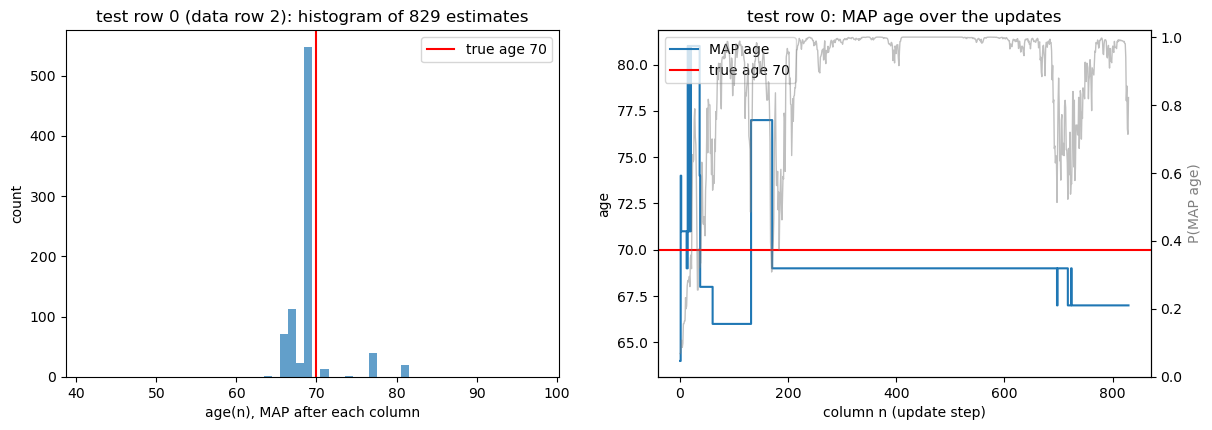

interactive(children=(IntSlider(value=0, description='r', max=241), Dropdown(description='use', options=('MAP'…

In [30]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

n_rows, n_cols = Y.shape
n_bins = 50
alpha = 1.0          # Laplace smoothing
prior_sd = 10.0      # width of the Gaussian prior around age 70
test_frac = 0.2
seed = 0

age = x[:, 1]

# ---------- train / test split ----------
rng = np.random.default_rng(seed)
perm = rng.permutation(n_rows)
n_test = int(round(test_frac * n_rows))
test_idx, train_idx = np.sort(perm[:n_test]), np.sort(perm[n_test:])
n_train = len(train_idx)

age_tr = age[train_idx]
has_age_tr = ~np.isnan(age_tr)
grid = np.unique(age_tr[has_age_tr])                 # candidate ages come from the training set
n_a = len(grid)
a_idx_tr = np.full(n_train, -1)
a_idx_tr[has_age_tr] = np.searchsorted(grid, age_tr[has_age_tr])

# ---------- sequential Bayes update on the test rows ----------
logpost = np.tile(-0.5 * ((grid - 70) / prior_sd) ** 2, (n_test, 1))
age_map  = np.zeros((n_test, n_cols))
p_map    = np.zeros((n_test, n_cols))
age_mean = np.zeros((n_test, n_cols))
rows_ar = np.arange(n_test)

for j in range(n_cols):
    y_tr = Y[train_idx, j]
    y_te = Y[test_idx, j]
    v_tr = ~np.isnan(y_tr)
    v_te = ~np.isnan(y_te)

    if v_tr.any():
        edges = np.histogram_bin_edges(y_tr[v_tr], bins=n_bins)       # edges from training data only

        b_tr = np.full(n_train, -1)
        b_tr[v_tr] = np.clip(np.digitize(y_tr[v_tr], edges[1:-1]), 0, n_bins - 1)
        use = v_tr & has_age_tr
        counts = np.bincount(a_idx_tr[use] * n_bins + b_tr[use],
                             minlength=n_a * n_bins).reshape(n_a, n_bins)
        logL = np.log((counts + alpha) / (counts.sum(1, keepdims=True) + alpha * n_bins))

        b_te = np.full(n_test, -1)
        b_te[v_te] = np.clip(np.digitize(y_te[v_te], edges[1:-1]), 0, n_bins - 1)  # outside values go to the end bins
        logpost[v_te] += logL[:, b_te[v_te]].T                         # NaN test values are skipped
        logpost -= logpost.max(1, keepdims=True)

    post = np.exp(logpost)
    post /= post.sum(1, keepdims=True)                                 # posterior = next prior
    k = post.argmax(1)
    age_map[:, j] = grid[k]
    p_map[:, j] = post[rows_ar, k]
    age_mean[:, j] = post @ grid

# ---------- evaluation on the test rows ----------
true_te = age[test_idx]
ok = ~np.isnan(true_te)
final = age_map[:, -1]
print(f"train rows: {n_train}, test rows: {n_test}")
print(f"MAE final MAP age:        {np.mean(np.abs(final[ok] - true_te[ok])):.2f}")
print(f"MAE constant 70:          {np.mean(np.abs(70 - true_te[ok])):.2f}")
print(f"MAE train mean age:       {np.mean(np.abs(np.nanmean(age_tr) - true_te[ok])):.2f}")
print(f"mean P(MAP) at the end:   {p_map[:, -1].mean():.2f}")

# ---------- plots for one test row ----------
def draw_row(r=0, use="MAP"):
    est = age_map[r] if use == "MAP" else age_mean[r]
    true = true_te[r]
    steps = np.arange(1, n_cols + 1)

    fig, (axh, axt) = plt.subplots(1, 2, figsize=(14, 4.5))

    axh.hist(est, bins=np.arange(grid.min() - 0.5, grid.max() + 1.5, 1), alpha=0.7)
    axh.axvline(true, color="red", label=f"true age {true:.0f}")
    axh.set_xlabel(f"age(n), {use} after each column")
    axh.set_ylabel("count")
    axh.set_title(f"test row {r} (data row {test_idx[r]}): histogram of {n_cols} estimates")
    axh.legend()

    axt.step(steps, est, where="post", label=f"{use} age")
    axt.axhline(true, color="red", label=f"true age {true:.0f}")
    axt.set_xlabel("column n (update step)")
    axt.set_ylabel("age")
    axt.set_title(f"test row {r}: {use} age over the updates")
    axt.legend(loc="upper left")

    axp = axt.twinx()
    axp.plot(steps, p_map[r], color="gray", alpha=0.5, lw=1)
    axp.set_ylabel("P(MAP age)", color="gray")
    axp.set_ylim(0, 1.02)

    plt.show()

widgets.interact(draw_row, r=widgets.IntSlider(value=0, min=0, max=n_test - 1),
                 use=["MAP", "mean"]);

In [31]:
# feature selection using feature importance from RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(df_X_train, df_y_train.iloc[:, 1].values)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
top_n = 100
top_n_indices = indices[:top_n]
df_X_train = df_X_train.iloc[:, top_n_indices]
df_X_test = df_X_test.iloc[:, top_n_indices]



df_X_train

,x115,x458,x507,x415,x742,x465,x334,x133,x242,x641,...,x640,x92,x554,x424,x230,x369,x87,x276,x77,x502
0,12802.203605,2535.339350,544.374242,643.545179,50599.080529,3459.272794,7021.868049,3562.654007,1641.687814,103.324048,...,2.304119,2.810519,1.410215e+06,10.142002,-87267.926038,8417.056102,9496.005953,3.306871,2262.036171,14368.954220
1,1921.015297,1331.849779,NaN,465.147469,199281.283029,4250.658655,8624.598353,4373.986953,1706.197779,14.906089,...,2.615888,2.512001,1.749833e+06,10.768402,-110669.290930,10943.049756,11212.089706,4.052621,2264.003373,NaN
2,2167.802432,772.966759,170.420569,295.848120,46047.033176,2983.325516,6227.949420,NaN,1197.877859,NaN,...,2.517927,2.900569,1.384469e+06,11.007380,-89976.325977,8240.053498,9277.004195,3.319240,2271.065213,NaN
3,12432.203273,1753.694685,1466.303159,1554.915684,31211.083229,NaN,3364.509427,1643.125832,509.564736,NaN,...,1.987144,2.798566,9.805791e+05,10.548248,-45006.918734,4168.048885,3496.051763,2.567630,886.607249,8710.651475
4,6424.918043,2277.884486,942.335830,815.023397,53680.071640,3796.544564,7728.437986,3931.946351,1883.096799,99.185290,...,2.466414,2.908099,1.541784e+06,10.804411,-94544.472618,8537.004503,8629.004273,3.148173,1776.059263,14246.231755
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1207,1995.689353,1525.961784,691.216961,532.526090,NaN,4410.360169,8647.503648,4237.248178,1378.996031,53.519411,...,2.309572,2.744742,1.763950e+06,11.056067,-115883.974718,10336.082083,9581.023502,3.626580,2296.017472,18633.731944
1208,4141.182106,2020.712657,1592.730333,803.543980,56243.006662,3820.108885,7440.294184,3620.152732,1652.352245,151.068992,...,2.152012,2.769824,1.703301e+06,11.009167,-103395.059722,9699.097262,10020.022198,3.221972,1740.037226,17365.636197
1209,2433.848973,NaN,297.909298,198.912907,167047.243881,3991.612952,8025.236403,4033.644491,1328.921728,62.119179,...,2.394156,2.590935,1.436486e+06,10.356493,-97233.536714,8680.072490,8685.026317,3.603263,2406.053930,14969.459781
1210,4703.596560,3537.792852,2314.121277,2380.486911,44573.025033,2465.879865,5336.757640,2870.940381,1388.018000,73.922040,...,2.311869,2.724816,1.608328e+06,NaN,-94713.157281,8101.007428,8517.089186,3.132653,2152.071772,14470.993407


train rows: 970, test rows: 242, passes: 3
pass 1: MAE 7.12   mean P(MAP) 0.92
pass 2: MAE 7.12   mean P(MAP) 0.96
pass 3: MAE 7.12   mean P(MAP) 0.97
baseline MAE constant 70:    7.02
baseline MAE train mean age: 7.05


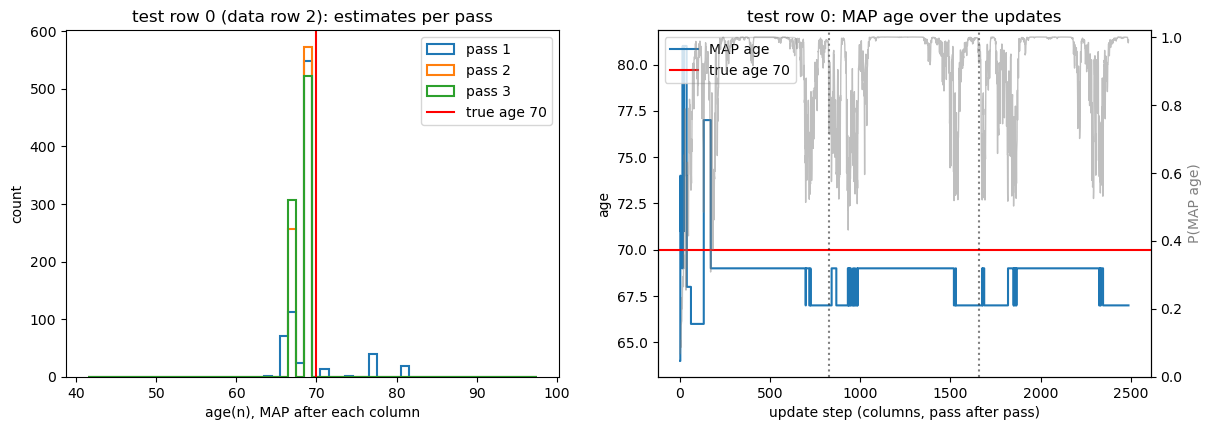

interactive(children=(IntSlider(value=0, description='r', max=241), Dropdown(description='use', options=('MAP'…

In [32]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

n_rows, n_cols = Y.shape
n_bins = 50
alpha = 1.0
prior_sd = 10.0
test_frac = 0.2
seed = 0
n_passes = 3
shuffle_cols = False

age = x[:, 1]

# ---------- train / test split ----------
rng = np.random.default_rng(seed)
perm = rng.permutation(n_rows)
n_test = int(round(test_frac * n_rows))
test_idx, train_idx = np.sort(perm[:n_test]), np.sort(perm[n_test:])
n_train = len(train_idx)

age_tr = age[train_idx]
has_age_tr = ~np.isnan(age_tr)
grid = np.unique(age_tr[has_age_tr])
n_a = len(grid)
a_idx_tr = np.full(n_train, -1)
a_idx_tr[has_age_tr] = np.searchsorted(grid, age_tr[has_age_tr])

# ---------- precompute likelihood tables and test bins (training data only) ----------
logL_all = np.zeros((n_cols, n_a, n_bins))
b_te_all = np.full((n_test, n_cols), -1)
has_tab = np.zeros(n_cols, dtype=bool)

for j in range(n_cols):
    y_tr = Y[train_idx, j]
    y_te = Y[test_idx, j]
    v_tr = ~np.isnan(y_tr)
    v_te = ~np.isnan(y_te)
    if not v_tr.any():
        continue
    edges = np.histogram_bin_edges(y_tr[v_tr], bins=n_bins)
    b_tr = np.full(n_train, -1)
    b_tr[v_tr] = np.clip(np.digitize(y_tr[v_tr], edges[1:-1]), 0, n_bins - 1)
    use = v_tr & has_age_tr
    counts = np.bincount(a_idx_tr[use] * n_bins + b_tr[use],
                         minlength=n_a * n_bins).reshape(n_a, n_bins)
    logL_all[j] = np.log((counts + alpha) / (counts.sum(1, keepdims=True) + alpha * n_bins))
    b_te_all[v_te, j] = np.clip(np.digitize(y_te[v_te], edges[1:-1]), 0, n_bins - 1)
    has_tab[j] = True

# ---------- sequential Bayes update: n_passes passes through the columns ----------
n_steps = n_passes * n_cols
logpost = np.tile(-0.5 * ((grid - 70) / prior_sd) ** 2, (n_test, 1))
age_map  = np.zeros((n_test, n_steps))
p_map    = np.zeros((n_test, n_steps))
age_mean = np.zeros((n_test, n_steps))
rows_ar = np.arange(n_test)

step = 0
for p in range(n_passes):
    order = rng.permutation(n_cols) if shuffle_cols else np.arange(n_cols)
    for j in order:
        if has_tab[j]:
            b = b_te_all[:, j]
            v = b >= 0
            logpost[v] += logL_all[j][:, b[v]].T         # NaN test values are skipped
            logpost -= logpost.max(1, keepdims=True)
        post = np.exp(logpost)
        post /= post.sum(1, keepdims=True)               # posterior = next prior
        k = post.argmax(1)
        age_map[:, step] = grid[k]
        p_map[:, step] = post[rows_ar, k]
        age_mean[:, step] = post @ grid
        step += 1

# ---------- evaluation on the test rows ----------
true_te = age[test_idx]
ok = ~np.isnan(true_te)
print(f"train rows: {n_train}, test rows: {n_test}, passes: {n_passes}")
for p in range(n_passes):
    final = age_map[:, (p + 1) * n_cols - 1]
    print(f"pass {p + 1}: MAE {np.mean(np.abs(final[ok] - true_te[ok])):.2f}   "
          f"mean P(MAP) {p_map[:, (p + 1) * n_cols - 1].mean():.2f}")
print(f"baseline MAE constant 70:    {np.mean(np.abs(70 - true_te[ok])):.2f}")
print(f"baseline MAE train mean age: {np.mean(np.abs(np.nanmean(age_tr) - true_te[ok])):.2f}")

# ---------- plots for one test row ----------
def draw_row(r=0, use="MAP"):
    est = age_map[r] if use == "MAP" else age_mean[r]
    true = true_te[r]
    steps = np.arange(1, n_steps + 1)
    bins = np.arange(grid.min() - 0.5, grid.max() + 1.5, 1)

    fig, (axh, axt) = plt.subplots(1, 2, figsize=(14, 4.5))

    for p in range(n_passes):                            # one histogram per pass
        axh.hist(est[p * n_cols:(p + 1) * n_cols], bins=bins, histtype="step", lw=1.5, label=f"pass {p + 1}")
    axh.axvline(true, color="red", label=f"true age {true:.0f}")
    axh.set_xlabel(f"age(n), {use} after each column")
    axh.set_ylabel("count")
    axh.set_title(f"test row {r} (data row {test_idx[r]}): estimates per pass")
    axh.legend()

    axt.step(steps, est, where="post", label=f"{use} age")
    axt.axhline(true, color="red", label=f"true age {true:.0f}")
    for p in range(1, n_passes):
        axt.axvline(p * n_cols, color="k", ls=":", alpha=0.5)    # pass boundaries
    axt.set_xlabel("update step (columns, pass after pass)")
    axt.set_ylabel("age")
    axt.set_title(f"test row {r}: {use} age over the updates")
    axt.legend(loc="upper left")

    axp = axt.twinx()
    axp.plot(steps, p_map[r], color="gray", alpha=0.5, lw=1)
    axp.set_ylabel("P(MAP age)", color="gray")
    axp.set_ylim(0, 1.02)

    plt.show()

widgets.interact(draw_row, r=widgets.IntSlider(value=0, min=0, max=n_test - 1),
                 use=["MAP", "mean"]);

train rows: 970, test rows: 242, passes: 3, temper: 0.1
pass 1: MAE MAP 7.00   MAE mean 6.62   mean P(MAP) 0.46
pass 2: MAE MAP 6.96   MAE mean 6.71   mean P(MAP) 0.67
pass 3: MAE MAP 7.12   MAE mean 6.78   mean P(MAP) 0.77
baseline MAE constant 70: 7.02   train mean age: 7.05

temper   MAE(MAP)  MAE(mean)  mean P(MAP)   [final step]


1            7.12       7.08         0.97


0.3          7.08       7.03         0.91


0.1          7.12       6.78         0.77


0.03         7.02       6.60         0.42


0.01         7.07       6.62         0.16


0.003        6.93       6.81         0.06


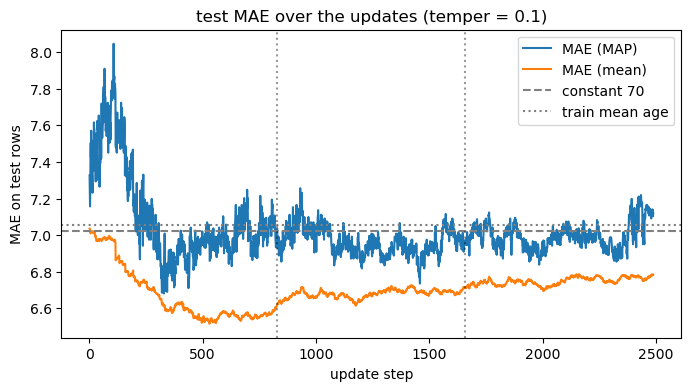

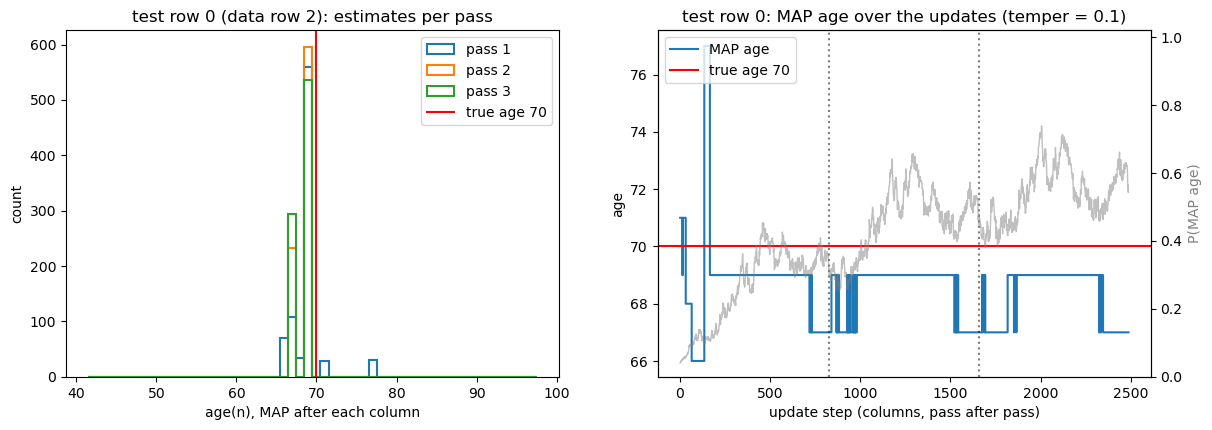

interactive(children=(IntSlider(value=0, description='r', max=241), Dropdown(description='use', options=('MAP'…

In [33]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

n_rows, n_cols = Y.shape
n_bins = 50
alpha = 1.0
prior_sd = 10.0
test_frac = 0.2
seed = 0
n_passes = 3
shuffle_cols = False
temper = 0.1                      # likelihood exponent: 1 = full Bayes, <1 = tempered
temper_sweep = [1, 0.3, 0.1, 0.03, 0.01, 0.003]

age = x[:, 1]

# ---------- train / test split ----------
rng = np.random.default_rng(seed)
perm = rng.permutation(n_rows)
n_test = int(round(test_frac * n_rows))
test_idx, train_idx = np.sort(perm[:n_test]), np.sort(perm[n_test:])
n_train = len(train_idx)

age_tr = age[train_idx]
has_age_tr = ~np.isnan(age_tr)
grid = np.unique(age_tr[has_age_tr])
n_a = len(grid)
a_idx_tr = np.full(n_train, -1)
a_idx_tr[has_age_tr] = np.searchsorted(grid, age_tr[has_age_tr])

true_te = age[test_idx]
ok = ~np.isnan(true_te)

# ---------- precompute likelihood tables and test bins (training data only) ----------
logL_all = np.zeros((n_cols, n_a, n_bins))
b_te_all = np.full((n_test, n_cols), -1)
has_tab = np.zeros(n_cols, dtype=bool)

for j in range(n_cols):
    y_tr = Y[train_idx, j]
    y_te = Y[test_idx, j]
    v_tr = ~np.isnan(y_tr)
    v_te = ~np.isnan(y_te)
    if not v_tr.any():
        continue
    edges = np.histogram_bin_edges(y_tr[v_tr], bins=n_bins)
    b_tr = np.full(n_train, -1)
    b_tr[v_tr] = np.clip(np.digitize(y_tr[v_tr], edges[1:-1]), 0, n_bins - 1)
    use = v_tr & has_age_tr
    counts = np.bincount(a_idx_tr[use] * n_bins + b_tr[use],
                         minlength=n_a * n_bins).reshape(n_a, n_bins)
    logL_all[j] = np.log((counts + alpha) / (counts.sum(1, keepdims=True) + alpha * n_bins))
    b_te_all[v_te, j] = np.clip(np.digitize(y_te[v_te], edges[1:-1]), 0, n_bins - 1)
    has_tab[j] = True

# ---------- sequential Bayes update with tempering ----------
log_prior = -0.5 * ((grid - 70) / prior_sd) ** 2
rows_ar = np.arange(n_test)

def bayes_run(temper, n_passes=n_passes):
    r = np.random.default_rng(seed)
    logpost = np.tile(log_prior, (n_test, 1))
    n_steps = n_passes * n_cols
    a_map = np.zeros((n_test, n_steps))
    p_m = np.zeros((n_test, n_steps))
    a_mean = np.zeros((n_test, n_steps))
    step = 0
    for p in range(n_passes):
        order = r.permutation(n_cols) if shuffle_cols else np.arange(n_cols)
        for j in order:
            if has_tab[j]:
                b = b_te_all[:, j]
                v = b >= 0
                logpost[v] += temper * logL_all[j][:, b[v]].T      # tempered update
                logpost -= logpost.max(1, keepdims=True)
            post = np.exp(logpost)
            post /= post.sum(1, keepdims=True)
            k = post.argmax(1)
            a_map[:, step] = grid[k]
            p_m[:, step] = post[rows_ar, k]
            a_mean[:, step] = post @ grid
            step += 1
    return a_map, p_m, a_mean

def mae_steps(est):                                   # MAE over test rows at every step
    return np.mean(np.abs(est[ok] - true_te[ok, None]), axis=0)

# ---------- main run ----------
age_map, p_map, age_mean = bayes_run(temper)
mae_map, mae_mean = mae_steps(age_map), mae_steps(age_mean)

base_const = np.mean(np.abs(70 - true_te[ok]))
base_mean = np.mean(np.abs(np.nanmean(age_tr) - true_te[ok]))

print(f"train rows: {n_train}, test rows: {n_test}, passes: {n_passes}, temper: {temper}")
for p in range(n_passes):
    e = (p + 1) * n_cols - 1
    print(f"pass {p + 1}: MAE MAP {mae_map[e]:.2f}   MAE mean {mae_mean[e]:.2f}   mean P(MAP) {p_map[:, e].mean():.2f}")
print(f"baseline MAE constant 70: {base_const:.2f}   train mean age: {base_mean:.2f}")

# ---------- sweep over tempering values ----------
print("\ntemper   MAE(MAP)  MAE(mean)  mean P(MAP)   [final step]")
for t in temper_sweep:
    a_m, p_m, a_me = bayes_run(t)
    print(f"{t:<8} {mae_steps(a_m)[-1]:8.2f}  {mae_steps(a_me)[-1]:9.2f}  {p_m[:, -1].mean():11.2f}")

# ---------- MAE vs update step ----------
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, n_passes * n_cols + 1), mae_map, label="MAE (MAP)")
ax.plot(np.arange(1, n_passes * n_cols + 1), mae_mean, label="MAE (mean)")
ax.axhline(base_const, color="gray", ls="--", label="constant 70")
ax.axhline(base_mean, color="gray", ls=":", label="train mean age")
for p in range(1, n_passes):
    ax.axvline(p * n_cols, color="k", ls=":", alpha=0.4)
ax.set_xlabel("update step")
ax.set_ylabel("MAE on test rows")
ax.set_title(f"test MAE over the updates (temper = {temper})")
ax.legend()
plt.show()

# ---------- plots for one test row ----------
def draw_row(r=0, use="MAP"):
    est = age_map[r] if use == "MAP" else age_mean[r]
    true = true_te[r]
    n_steps = n_passes * n_cols
    steps = np.arange(1, n_steps + 1)
    bins = np.arange(grid.min() - 0.5, grid.max() + 1.5, 1)

    fig, (axh, axt) = plt.subplots(1, 2, figsize=(14, 4.5))
    for p in range(n_passes):
        axh.hist(est[p * n_cols:(p + 1) * n_cols], bins=bins, histtype="step", lw=1.5, label=f"pass {p + 1}")
    axh.axvline(true, color="red", label=f"true age {true:.0f}")
    axh.set_xlabel(f"age(n), {use} after each column")
    axh.set_ylabel("count")
    axh.set_title(f"test row {r} (data row {test_idx[r]}): estimates per pass")
    axh.legend()

    axt.step(steps, est, where="post", label=f"{use} age")
    axt.axhline(true, color="red", label=f"true age {true:.0f}")
    for p in range(1, n_passes):
        axt.axvline(p * n_cols, color="k", ls=":", alpha=0.5)
    axt.set_xlabel("update step (columns, pass after pass)")
    axt.set_ylabel("age")
    axt.set_title(f"test row {r}: {use} age over the updates (temper = {temper})")
    axt.legend(loc="upper left")

    axp = axt.twinx()
    axp.plot(steps, p_map[r], color="gray", alpha=0.5, lw=1)
    axp.set_ylabel("P(MAP age)", color="gray")
    axp.set_ylim(0, 1.02)
    plt.show()

widgets.interact(draw_row, r=widgets.IntSlider(value=0, min=0, max=n_test - 1),
                 use=["MAP", "mean"]);

In [1]:
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

known = ~np.isnan(age)
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      RidgeCV(alphas=np.logspace(0, 5, 11)))
pred = cross_val_predict(model, Y[known], age[known],
                         cv=KFold(5, shuffle=True, random_state=0))
print("ridge CV MAE:", np.mean(np.abs(pred - age[known])))

NameError: name 'np' is not defined

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

known_idx = np.where(~np.isnan(age))[0]
Yk, ak = Y[known_idx], age[known_idx]
cv = KFold(5, shuffle=True, random_state=0)
k_list = [5, 10, 20, 40, 80]            # number of principal components to try

def fit_bayes(Y_tr, a_tr, k):
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         PCA(n_components=k, random_state=0))
    Z = pipe.fit_transform(Y_tr)                        # decorrelated components
    am, asd = a_tr.mean(), a_tr.std()
    ac = a_tr - am
    b = (Z.T @ ac) / (ac @ ac)                          # slope of each component on age
    a0 = Z.mean(0)                                      # intercept
    s2 = (Z - a0 - np.outer(ac, b)).var(0, ddof=2)      # residual variance per component
    return pipe, a0, b, s2, np.unique(a_tr), am, asd

def posterior(model, Y_te):
    pipe, a0, b, s2, grid, am, asd = model
    Z = pipe.transform(Y_te)
    mean = a0[None, None, :] + b[None, None, :] * (grid - am)[None, :, None]   # (1, G, k)
    ll = -0.5 * (((Z[:, None, :] - mean) ** 2) / s2).sum(2)                    # (n, G)
    lpost = ll - 0.5 * ((grid - am) / asd) ** 2                                # + Gaussian prior on age
    lpost -= lpost.max(1, keepdims=True)
    post = np.exp(lpost)
    return grid, post / post.sum(1, keepdims=True)

def summarize(grid, post):
    cdf = np.cumsum(post, 1)
    q = lambda u: grid[(cdf >= u).argmax(1)]
    return dict(mean=post @ grid, median=q(0.5), map=grid[post.argmax(1)], lo=q(0.05), hi=q(0.95))

def cv_bayes(k):
    out = {key: np.zeros(len(ak)) for key in ["mean", "median", "map", "lo", "hi"]}
    for tr, te in cv.split(Yk):
        model = fit_bayes(Yk[tr], ak[tr], k)
        grid, post = posterior(model, Yk[te])
        for key, v in summarize(grid, post).items():
            out[key][te] = v
    return out

base_pred = np.zeros_like(ak)
for tr, te in cv.split(Yk):
    base_pred[te] = ak[tr].mean()
print(f"baseline (train mean) MAE: {np.mean(np.abs(base_pred - ak)):.2f}")
if "pred" in globals():
    print(f"ridge MAE (earlier cell):  {np.mean(np.abs(pred - ak)):.2f}")

print("\n k    MAE(median) MAE(mean) MAE(MAP)  90% coverage")
res = {}
for k in k_list:
    r = cv_bayes(k)
    res[k] = r
    cover = np.mean((ak >= r["lo"]) & (ak <= r["hi"]))
    print(f"{k:3d}   {np.mean(np.abs(r['median']-ak)):9.2f} {np.mean(np.abs(r['mean']-ak)):9.2f} "
          f"{np.mean(np.abs(r['map']-ak)):8.2f}  {cover:11.2f}")

best_k = min(k_list, key=lambda k: np.mean(np.abs(res[k]["median"] - ak)))
r = res[best_k]
print(f"\nbest k = {best_k}")
plt.figure(figsize=(6, 5))
plt.scatter(ak, r["median"], s=8, alpha=0.6)
plt.plot([ak.min(), ak.max()], [ak.min(), ak.max()], "k--")
plt.xlabel("true age"); plt.ylabel("posterior median (CV)"); plt.title(f"Bayesian PCA model, k = {best_k}")
plt.show()

NameError: name 'age' is not defined

In [3]:
# fill missing values with KNN imputer (faster and more stable than iterative)
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
df_X_train = pd.DataFrame(imputer.fit_transform(df_X_train), columns=df_X_train.columns)
df_X_test = pd.DataFrame(imputer.transform(df_X_test), columns=df_X_test.columns)

df_X_train

NameError: name 'pd' is not defined

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict

known = ~np.isnan(age)
Yk, ak = Y[known], age[known]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as the ridge cell

common = dict(learning_rate=0.05, max_iter=500, max_depth=3, min_samples_leaf=20,
              l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
              n_iter_no_change=20, random_state=0)
preds = {}
for name, loss in [("GB squared_error", "squared_error"), ("GB absolute_error", "absolute_error")]:
    model = HistGradientBoostingRegressor(loss=loss, **common)
    preds[name] = cross_val_predict(model, Yk, ak, cv=cv)

base_pred = np.zeros_like(ak)
for tr, te in cv.split(ak):
    base_pred[te] = ak[tr].mean()
mae = lambda p_: np.mean(np.abs(p_ - ak))
print(f"baseline (train mean) MAE: {mae(base_pred):.2f}")
if "pred" in globals():
    print(f"ridge MAE (earlier cell):  {mae(pred):.2f}")
for name, p_ in preds.items():
    print(f"{name} MAE:   {mae(p_):.2f}")
best = min(preds, key=lambda k: mae(preds[k]))
if "pred" in globals():
    print(f"average of ridge and {best}: {mae((pred + preds[best]) / 2):.2f}")

p_best = preds[best]
print(f"\nMAE by true age group ({best}):")
for lo, hi in [(40, 55), (55, 65), (65, 75), (75, 85), (85, 100)]:
    m = (ak >= lo) & (ak < hi)
    print(f"  {lo}-{hi}: n={m.sum():4d}  MAE={np.mean(np.abs(p_best[m] - ak[m])):.2f}")

plt.figure(figsize=(6, 5))
plt.scatter(ak, p_best, s=8, alpha=0.6)
plt.plot([ak.min(), ak.max()], [ak.min(), ak.max()], "k--")
plt.xlabel("true age"); plt.ylabel("CV prediction"); plt.title(best)
plt.show()

NameError: name 'age' is not defined

In [5]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

known_idx = np.where(~np.isnan(age))[0]
Yk, ak = Y[known_idx], age[known_idx]
cv = KFold(5, shuffle=True, random_state=0)           # same folds as ridge and GB
k_list = [10, 20, 40]                                 # PCA components
deg_list = [1, 2, 3, 4]                               # polynomial degree in age (1 = the earlier linear model)

def basis(a, am, asd, deg):
    return np.vander((a - am) / asd, deg + 1, increasing=True)      # columns 1, t, t^2, ...

def fit_poly(Z, a_tr, am, asd, deg):
    B = basis(a_tr, am, asd, deg)
    coef, *_ = np.linalg.lstsq(B, Z, rcond=None)                     # (deg+1, k)
    s2 = ((Z - B @ coef) ** 2).sum(0) / (len(a_tr) - deg - 1)        # residual variance per component
    return coef, s2

def posterior(Z_te, coef, s2, grid, am, asd, deg):
    mean = basis(grid, am, asd, deg) @ coef                          # (G, k): mean of each component at each age
    ll = -0.5 * (((Z_te[:, None, :] - mean[None]) ** 2) / s2).sum(2)
    lpost = ll - 0.5 * ((grid - am) / asd) ** 2                      # + Gaussian prior on age
    lpost -= lpost.max(1, keepdims=True)
    post = np.exp(lpost)
    return post / post.sum(1, keepdims=True)

def summarize(grid, post):
    cdf = np.cumsum(post, 1)
    q = lambda u: grid[(cdf >= u).argmax(1)]
    return dict(mean=post @ grid, median=q(0.5), lo=q(0.05), hi=q(0.95))

res = {(k, d): {key: np.zeros(len(ak)) for key in ["mean", "median", "lo", "hi"]}
       for k in k_list for d in deg_list}
for tr, te in cv.split(Yk):
    am, asd = ak[tr].mean(), ak[tr].std()
    grid = np.unique(ak[tr])
    for k in k_list:
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             PCA(n_components=k, random_state=0))
        Z_tr = pipe.fit_transform(Yk[tr])
        Z_te = pipe.transform(Yk[te])
        for d in deg_list:
            coef, s2 = fit_poly(Z_tr, ak[tr], am, asd, d)
            post = posterior(Z_te, coef, s2, grid, am, asd, d)
            for key, v in summarize(grid, post).items():
                res[(k, d)][key][te] = v

base_pred = np.zeros_like(ak)
for tr, te in cv.split(ak):
    base_pred[te] = ak[tr].mean()
mae = lambda p_: np.mean(np.abs(p_ - ak))
print(f"baseline (train mean) MAE: {mae(base_pred):.2f}")
if "pred" in globals():
    print(f"ridge MAE (earlier cell):  {mae(pred):.2f}")
print("GB squared_error (earlier): 5.37")
print("\n  k  degree  MAE(median)  MAE(mean)  90% coverage")
for (k, d), r in res.items():
    cover = np.mean((ak >= r["lo"]) & (ak <= r["hi"]))
    print(f"{k:3d}  {d:6d}  {mae(r['median']):11.2f}  {mae(r['mean']):9.2f}  {cover:12.2f}")

best = min(res, key=lambda kd: mae(res[kd]["median"]))
p_best = res[best]["median"]
print(f"\nbest: k = {best[0]}, degree = {best[1]}")
print("MAE by true age group (best):")
for lo, hi in [(40, 55), (55, 65), (65, 75), (75, 85), (85, 100)]:
    m = (ak >= lo) & (ak < hi)
    print(f"  {lo}-{hi}: n={m.sum():4d}  MAE={np.mean(np.abs(p_best[m] - ak[m])):.2f}")

NameError: name 'age' is not defined

In [ ]:
import numpy as np, warnings
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.svm import SVR
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")
rng = np.random.default_rng(5)

age = np.asarray(age, dtype=float)
col_med = np.nanmedian(Y, 0); col_med[(col_med == 0) | np.isnan(col_med)] = 1.0
rf = np.nanmedian(Y / col_med, 1)
rf = np.where(rf > 0, rf, np.nan); rf = np.where(np.isnan(rf), np.nanmedian(rf), rf)
known = ~np.isnan(age); ak = age[known]
F = Y / rf[:, None]; F = np.where(np.isfinite(F), F, np.nan)[known]
keep = np.nanstd(F, 0) > 0                                  # drop constant columns, keep order
F = F[:, keep]; p = F.shape[1]

# ---- 1. is there structure in the column order? (ages not used here) ----
Z0 = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0).fit_transform(
        SimpleImputer(strategy="median").fit_transform(F))
Rk = np.apply_along_axis(rankdata, 0, Z0); Rk = (Rk - Rk.mean(0)) / Rk.std(0)
def lagcorr(l): return np.mean(np.sum(Rk[:, :-l] * Rk[:, l:], 0) / len(Rk))
lags = [1, 2, 3, 5, 10, 20, 50, 100, 300]
lc = [lagcorr(l) for l in lags]
Rp = Rk[:, rng.permutation(p)]
rand = np.mean(np.sum(Rp[:, :-1] * Rp[:, 1:], 0) / len(Rp))
print("mean correlation between columns j and j+lag (Spearman):")
for l, c in zip(lags, lc): print(f"   lag {l:>3}: {c:+.3f}")
print(f"   shuffled column order, lag 1: {rand:+.3f}   <- what 'no structure' looks like")

rho = np.nan_to_num(np.array([spearmanr(Z0[:, j], ak)[0] for j in range(p)]))
print(f"lag-1 autocorrelation of the age-correlation along column index: {np.corrcoef(rho[:-1], rho[1:])[0,1]:+.3f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(rho, lw=.7); ax[0].axhline(0, c="k", lw=.5); ax[0].set(title="Spearman rho(column, age) along column index", xlabel="column index")
ax[1].semilogx(lags, lc, "o-"); ax[1].set(title="column correlation vs lag", xlabel="lag"); plt.tight_layout(); plt.show()

# ---- 2. does adding neighbour features help the SVR? ----
def smooth(Z, w):
    k = np.ones(w) / w
    return np.apply_along_axis(lambda r: np.convolve(r, k, mode="same"), 1, Z)
def feats(Z, mode):
    if mode == "base": return Z
    D = Z[:, 1:] - Z[:, :-1]; S = smooth(Z, 5)
    return {"+diff": np.hstack([Z, D]), "+smooth": np.hstack([Z, S]), "+both": np.hstack([Z, D, S])}[mode]

K, C, GM = 150, 30, 1
cv = KFold(5, shuffle=True, random_state=0)
edges = [40, 55, 65, 75, 85, 100]
for mode in ["base", "+diff", "+smooth", "+both"]:
    pred = np.zeros(len(ak))
    for tr, te in cv.split(F):
        imp = SimpleImputer(strategy="median")
        qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0)
        Ztr = qt.fit_transform(imp.fit_transform(F[tr])); Zte = qt.transform(imp.transform(F[te]))
        Atr, Ate = feats(Ztr, mode), feats(Zte, mode)
        sc = StandardScaler().fit(Atr); Atr, Ate = sc.transform(Atr), sc.transform(Ate)
        cols = np.argsort(-np.nan_to_num(f_regression(Atr, ak[tr])[0]))[:K]
        pred[te] = SVR(kernel="rbf", C=C, gamma=GM / K).fit(Atr[:, cols], ak[tr]).predict(Ate[:, cols])
    err = np.abs(pred - ak)
    g = "  ".join(f"{lo}-{hi}: {err[(ak>=lo)&(ak<hi)].mean():5.2f}" for lo, hi in zip(edges[:-1], edges[1:]))
    print(f"{mode:9s} R2 {r2_score(ak, pred):.3f}  MAE {err.mean():.2f}   {g}")

In [ ]:
# feature selection using feature importance from RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(df_X_train, df_y_train.iloc[:, 1].values)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
top_n = 100
top_n_indices = indices[:top_n]
df_X_train = df_X_train.iloc[:, top_n_indices]
df_X_test = df_X_test.iloc[:, top_n_indices]



df_X_train

In [ ]:
# normalize features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_X_train = pd.DataFrame(scaler.fit_transform(df_X_train), columns=df_X_train.columns)
df_X_test = pd.DataFrame(scaler.transform(df_X_test), columns=df_X_test.columns)

In [ ]:
# training the model using HistGradientBoostingRegressor and 5-fold cross-validation and R2 score
from sklearn.model_selection import cross_val_score
model1 = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=7, min_samples_leaf=20, l2_regularization=1, max_leaf_nodes=50, random_state=42)
scores = cross_val_score(model1, df_X_train, df_y_train.iloc[:, 1].values, cv=5, scoring='r2')
print(f'Cross-validated R2 scores: {scores}')
print(f'Mean R2 score: {np.mean(scores)}')  


In [ ]:
# combining predictions from 3 runs of the above model with different random states scoring with voting regressor and R2 score 5-fold cross-validation  
model1a = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=7, min_samples_leaf=20, l2_regularization=1, max_leaf_nodes=50, random_state=1)
model1b = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=7, min_samples_leaf=20, l2_regularization=1, max_leaf_nodes=50, random_state=2)
model1c = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=7, min_samples_leaf=20, l2_regularization=1, max_leaf_nodes=50, random_state=3)
from sklearn.ensemble import VotingRegressor
ensemble_model = VotingRegressor(estimators=[('hgb1', model1a), ('hgb2', model1b), ('hgb3', model1c)])
scores = cross_val_score(ensemble_model, df_X_train, df_y_train.iloc[:, 1].values, cv=5, scoring='r2')
print(f'Cross-validated R2 scores: {scores}')
print(f'Mean R2 score: {np.mean(scores)}')  